# Proyecto Centinela · Fase 2 · Arquitecturas especializadas y fusión multimodal
## Centinela del Café: CNN (hoja) + LSTM/GRU (clima) + fusión

**Autores:** Briyith Lisdey Herrera Cruz · Juan Pablo Becerra Tirano · Johnatan Vélez Martínez
**Curso:** Deep Learning · Maestría en Ciencia de Datos · Universidad Santo Tomás

### ¿Qué resuelve este notebook?
| Rama | Pregunta que responde | Datos | Modelos |
|---|---|---|---|
| **A · Visión** | ¿La hoja está **sana**, tiene **ácaro rojo** o tiene **roya**? (3 clases) | 1.560 fotos de RoCoLe | ResNet50 vs EfficientNet-B0 · *feature extraction* vs *fine-tuning* · Grad-CAM |
| **B · Serie** | ¿Cuál será la **humedad relativa de mañana** en la finca? (la humedad es el motor de la roya) | 6.695 días de NASA POWER (2001–2019) | RNN simple (contraste) vs LSTM vs GRU |
| **C · Fusión** | ¿La hoja necesita **alerta de revisión**? (sí/no, como en la Fase 1) | Imagen + 60 días de clima previos | Fusión tardía + ablación |

### ¿Qué cambia frente a la Fase 1?
- **Antes:** la foto se "aplanaba" en 27 medidas de color y textura definidas a mano, y un MLP decidía.
- **Ahora:** una **red convolucional preentrenada** aprende sola qué mirar en la foto, una **red recurrente** modela el clima y ambas se **fusionan**.

**Lo que se conserva de la Fase 1, para comparar en igualdad de condiciones:**
- La partición por planta (`resultados/particion.csv`).
- La semilla 42.
- La regla de alerta: el umbral que minimiza 5·FN + FP en validación con *recall* ≥ 0,90.
- La línea base: MLP con AUC 0,936 y costo 54 en prueba.

### ¿En qué se diferencia del ejemplo público del curso?
La actividad usa "Centinela del Café" (RoCoLe + clima) como ejemplo de referencia y lo declara vetado como entrega. El equipo decidió continuar con RoCoLe (bitácora E-8) y construir un problema distinto:
1. **Clasificación visual de 3 clases** (sana / ácaro rojo / roya), que además alimenta una **alerta binaria con costos asimétricos**.
2. **Rama B como pronóstico de humedad** a un día con 18 años de datos, con evidencia medida del desvanecimiento del gradiente.
3. **Alineación medida, no supuesta:** se cuantifica cuánto varía el clima entre las fechas de las fotos y se prueba con una permutación si la fusión lo usa.
4. **Continuidad metodológica con la Fase 1:** partición por planta con duplicados agrupados y la misma regla de costo.

### Orden del notebook
0 · Configuración → 0.1 · Verificación de duplicados → Rama A (A1–A5) → Rama B (B1–B5) → Rama C (C1–C4) → Exportación.

## 0 · Configuración
**Qué hace este bloque:**
1. **Importa** las librerías: PyTorch y torchvision para las redes, scikit-learn para las métricas, statsmodels para ARIMA y la ACF, y matplotlib para las gráficas.
2. **Fija la semilla 42** en `random`, `numpy` y `torch`, y activa los algoritmos deterministas: cada ejecución da los mismos resultados.
3. **Usa todos los núcleos de la CPU**, o la GPU si existe (en Colab: Entorno de ejecución → T4).
4. **Define las carpetas:**

| Carpeta | Contenido |
|---|---|
| `data/raw/` | Fotos y anotaciones |
| `data/processed/fase2/` | Caché de hojas recortadas y rasgos |
| `resultados/fase2/` | Figuras, tablas y JSON |
| `modelos/fase2/` | Pesos `.pth` |

5. **Guarda las decisiones heredadas de la Fase 1:** costo FN:FP = 5:1, *recall* mínimo de 0,90 y coordenadas de la finca CIIDEA.
6. **Crea el diccionario `R2`**, donde se acumulan todas las cifras que luego cita el informe.

In [1]:
import sys
EN_COLAB = "google.colab" in sys.modules
import os, json, copy, math, time, random, hashlib, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import imagehash
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support, f1_score, roc_auc_score,
                             accuracy_score, mean_squared_error, mean_absolute_error)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")

from IPython.display import display

def ver_tabla(tabla, decimales=3):
    """Muestra una tabla en formato markdown (se ve igual en VS Code, Jupyter y Colab), con texto plano de respaldo."""
    md = tabla.round(decimales).to_markdown()          # enteros sin decimales; reales con hasta 3 decimales
    display({"text/markdown": md, "text/plain": tabla.to_string()}, raw=True)

SEMILLA = 42
def fijar_semillas(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
os.environ["PYTHONHASHSEED"] = str(SEMILLA)
fijar_semillas()
torch.use_deterministic_algorithms(True, warn_only=True)
torch.set_num_threads(os.cpu_count())
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CACHE = ROOT / "data" / "processed" / "fase2"
RES = ROOT / "resultados" / "fase2"
FIG = RES / "figuras"
MODELOS = ROOT / "modelos" / "fase2"
for c in (CACHE, RES, FIG, MODELOS):
    c.mkdir(parents=True, exist_ok=True)

COSTO_FN, COSTO_FP, RECALL_MIN = 5, 1, 0.90      # decisiones heredadas de la Fase 1
LAT, LON = -0.834206, -80.177159                  # CIIDEA, Manabí (Ecuador)
CLASES = ["sana", "ácaro rojo", "roya"]
COLOR = {"sana": "#1baf7a", "ácaro rojo": "#eda100", "roya": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
R2 = {"fecha_ejecucion": dt.date.today().isoformat(), "semilla": SEMILLA, "dispositivo": str(DISPOSITIVO)}
print("torch", torch.__version__, "| dispositivo:", DISPOSITIVO, "| hilos:", torch.get_num_threads())

torch 2.15.0+cpu | dispositivo: cpu | hilos: 12


## 0.1 · Antes de todo: ¿hay fotos duplicadas?
En la Fase 1 se encontraron fotos repetidas. Aquí se **vuelve a verificar** desde cero y con dos huellas distintas, porque si una foto aparece en entrenamiento y su copia en prueba, el modelo "ve el examen" y las métricas se inflan.

| Huella | Qué compara | Qué detecta |
|---|---|---|
| **SHA-256** | Los bytes del archivo | Copias **exactas**: el mismo archivo con otro nombre |
| **pHash** (*perceptual hash*) | La imagen reducida a 32×32 en grises, transformada a frecuencias (DCT) y resumida en 64 bits | Fotos **visualmente iguales**, aunque se hayan guardado de nuevo o recomprimido |

**Qué hace el bloque de código:**
1. Calcula ambas huellas para las 1.560 fotos.
2. Compara todos los pares de pHash: la **distancia de Hamming** cuenta cuántos de los 64 bits cambian.
3. Cuenta los pares a distancias 0, 2, 5 y 8. Distancia 0 significa visualmente idénticas; a mayor distancia, más diferencia.
4. Cruza el resultado con el SHA-256, para saber cuántas son copias exactas.

In [2]:
def huellas(ruta):
    im = Image.open(ruta); im.draft("RGB", (im.width // 2, im.height // 2))     # misma reducción que en la Fase 1
    return {"archivo": ruta.name, "sha256": hashlib.sha256(ruta.read_bytes()).hexdigest(), "phash": str(imagehash.phash(im.convert("RGB")))}

fotos = sorted((RAW / "Photos").glob("*.jpg"))
hue = pd.DataFrame([huellas(p) for p in fotos])
bits = np.array([np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8)) for h in hue["phash"]], dtype=np.int32)
dist = bits @ (1 - bits).T + (1 - bits) @ bits.T            # distancia de Hamming entre todos los pares
resumen_dup = []
for umbral in (0, 2, 5, 8):
    i, j = np.where(np.triu(dist <= umbral, k=1))
    exactos = int(sum(hue["sha256"].iat[a] == hue["sha256"].iat[b] for a, b in zip(i, j)))
    resumen_dup.append({"distancia_pHash_max": umbral, "pares": len(i), "pares_byte_a_byte": exactos, "pares_solo_visuales": len(i) - exactos})
resumen_dup = pd.DataFrame(resumen_dup)
grupos_sha = int((hue.groupby("sha256").size() > 1).sum())
R2["duplicados"] = {"grupos_sha256": grupos_sha, "por_distancia_phash": resumen_dup.to_dict(orient="records")}
print(f"Grupos de copias exactas (SHA-256): {grupos_sha}")
ver_tabla(resumen_dup)

Grupos de copias exactas (SHA-256): 67


|    |   distancia_pHash_max |   pares |   pares_byte_a_byte |   pares_solo_visuales |
|---:|----------------------:|--------:|--------------------:|----------------------:|
|  0 |                 0 |  68 |              67 |                 1 |
|  1 |                 2 |  75 |              67 |                 8 |
|  2 |                 5 |  82 |              67 |                15 |
|  3 |                 8 | 105 |              67 |                38 |

**Comprobación visual.** Los números no bastan: se muestran lado a lado algunos pares exactos y **todos** los pares casi idénticos (pHash ≤ 5) que no son copias byte a byte, con la clase que tiene cada copia en las anotaciones.

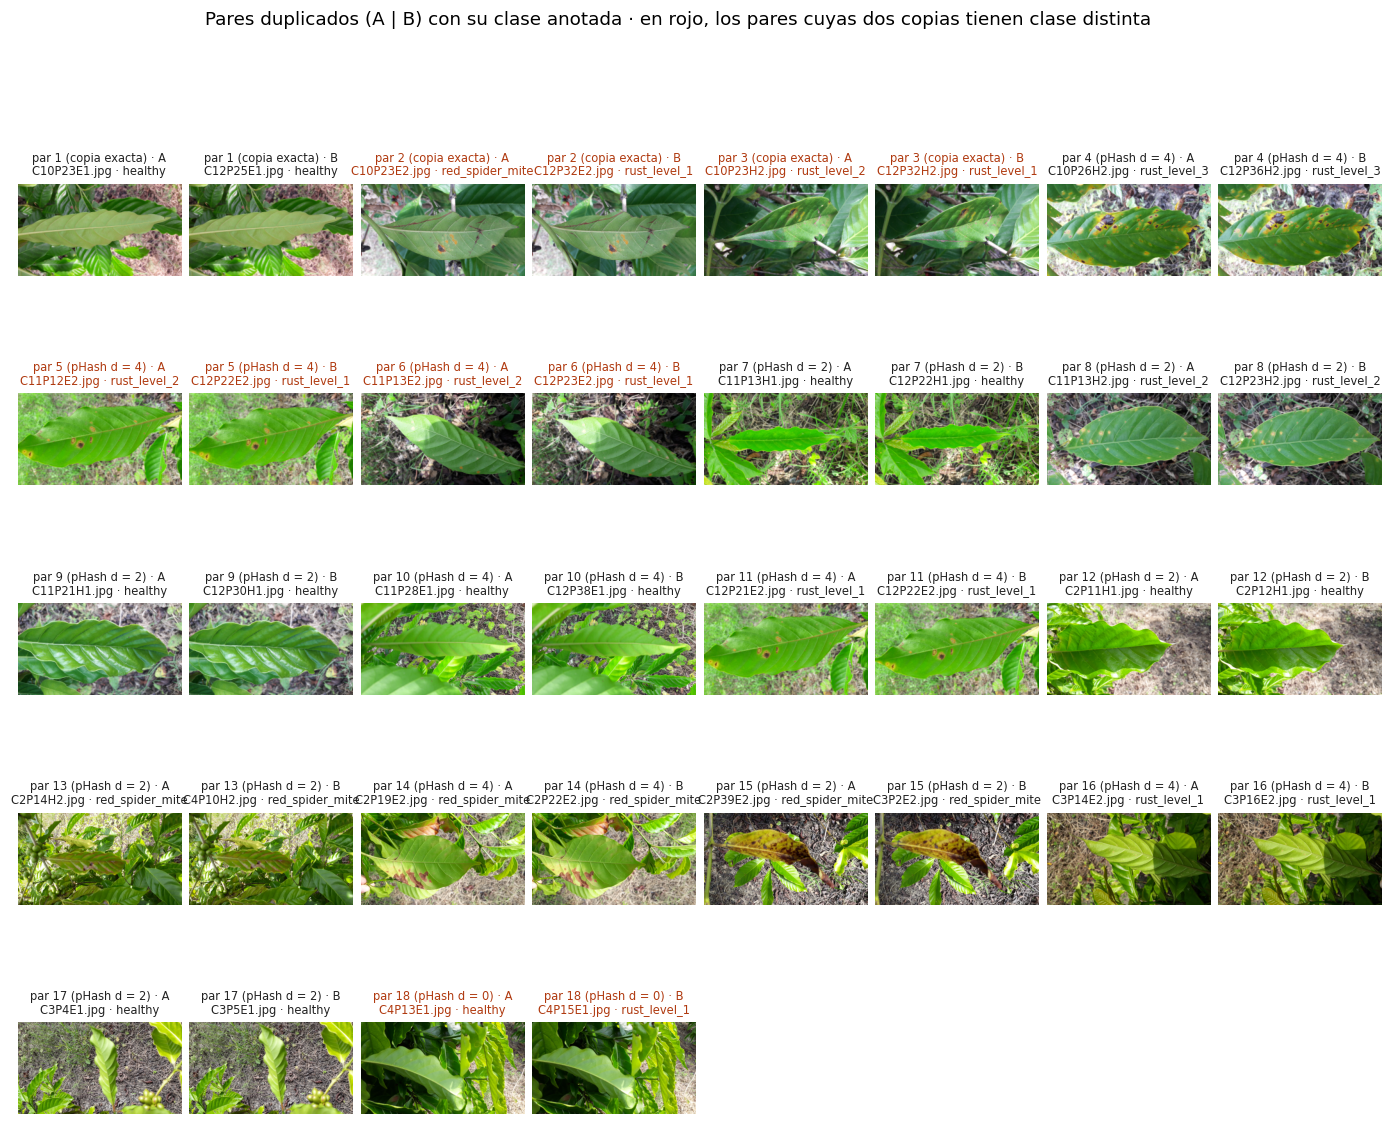

Pares con pHash ≤ 5 cuya clase anotada difiere entre las dos copias: 30 de 82


In [3]:
clase_original = pd.read_excel(RAW / "Annotations" / "RoCoLe-classes.xlsx").set_index("File")["Multiclass.Label"]
i, j = np.where(np.triu(dist <= 5, k=1))
pares = pd.DataFrame({"a": hue["archivo"].values[i], "b": hue["archivo"].values[j], "dist": dist[i, j],
                      "exacto": hue["sha256"].values[i] == hue["sha256"].values[j]})
mostrar = pd.concat([pares[pares["exacto"]].head(3), pares[~pares["exacto"]]]).reset_index(drop=True)
POR_FILA = 4; n_filas = int(np.ceil(len(mostrar) / POR_FILA))
fig, axes = plt.subplots(n_filas, POR_FILA * 2, figsize=(16, 2.3 * n_filas), gridspec_kw={"wspace": 0.05, "hspace": 0.55})
axes = np.atleast_2d(axes)
for k, f in mostrar.iterrows():
    r, c = divmod(k, POR_FILA)
    distinta = clase_original[f["a"]] != clase_original[f["b"]]
    tipo = "copia exacta" if f["exacto"] else f"pHash d = {f['dist']}"
    for j, nombre in enumerate((f["a"], f["b"])):
        ax = axes[r, 2 * c + j]
        im = Image.open(RAW / "Photos" / nombre); im.draft("RGB", (im.width // 8, im.height // 8))
        ax.imshow(im.convert("RGB")); ax.axis("off")
        ax.set_title(f"par {k + 1} ({tipo}) · {'A' if j == 0 else 'B'}\n{nombre} · {clase_original[nombre]}", fontsize=7.5,
                     color="#b03a10" if distinta else "#222222")
for ax in axes.ravel()[2 * len(mostrar):]:
    ax.axis("off")
fig.suptitle("Pares duplicados (A | B) con su clase anotada · en rojo, los pares cuyas dos copias tienen clase distinta", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "a0_duplicados.png", bbox_inches="tight"); plt.show()
distinta = int(sum(clase_original[a] != clase_original[b] for a, b in zip(pares["a"], pares["b"])))
R2["duplicados"]["pares_phash5_clase_distinta"] = distinta
print(f"Pares con pHash ≤ 5 cuya clase anotada difiere entre las dos copias: {distinta} de {len(pares)}")

**Lectura: la duplicidad SÍ existe y queda verificada.**
- **67 pares son copias exactas** (mismo SHA-256 y pHash idéntico). Siempre corresponden a **plantas distintas** según el nombre del archivo.
- Con pHash aparecen además **fotos visualmente iguales que no son el mismo archivo**: la misma foto guardada de nuevo. Al subir la tolerancia aparecen hojas muy parecidas.
- En varios pares, las dos copias tienen **clases distintas** en las anotaciones, por ejemplo "roya 4 / roya 3". Es **ruido de etiqueta** de la fuente: la misma imagen anotada dos veces de forma diferente.

**Decisión** (la misma de la Fase 1, ahora con verificación doble):
- Las fotos **no se eliminan**. Borrar una copia obligaría a elegir arbitrariamente cuál etiqueta es la "correcta".
- La partición que se reutiliza (`particion.csv`) ya **agrupa** las copias exactas y las casi idénticas (pHash ≤ 5), así que nunca quedan repartidas entre entrenamiento y prueba. La celda siguiente lo vuelve a comprobar.

## 1 · Datos de partida (heredados de la Fase 1)
**Qué hace este bloque:**
1. Lee la tabla de la Fase 1, con la clase, la fecha EXIF, el celular y la planta de cada foto.
2. Lee la **partición por planta** (70/15/15) y verifica que ningún par duplicado quede repartido entre dos subconjuntos.
3. Lee los **polígonos** que delimitan la hoja en cada foto, para recortarla. La columna `Created By`, que es un dato personal del anotador, no se usa.
4. Agrupa las 6 clases originales en las **3 categorías** que pide la actividad:
   - **sana**;
   - **ácaro rojo**;
   - **roya**, que reúne los niveles 1 a 4. Los niveles 3 (62 fotos) y 4 (30) son demasiado pocos para clasificarlos por separado.

> **Requisito para ejecutar:** las fotos y anotaciones de RoCoLe en `data/raw/` (`Photos/` y `Annotations/`). No vienen en el .zip por tamaño (unos 850 MB) y por licencia. Si no están, primero se ejecuta la sección 1.1 del notebook de la Fase 1, que las descarga de Mendeley Data (DOI 10.17632/c5yvn32dzg.2). La serie de NASA POWER sí viene incluida (`data/external/`).

In [4]:
tabla = pd.read_csv(ROOT / "data" / "processed" / "rocole_tabular_features_fase1.csv",
                    usecols=["archivo", "planta", "cara", "clase", "afectada", "fecha_txt", "dispositivo"])
particion = pd.read_csv(ROOT / "resultados" / "particion.csv")[["archivo", "id_grupo", "subconjunto"]]
tabla = tabla.merge(particion, on="archivo", validate="one_to_one")
tabla["clase3"] = tabla["clase"].where(tabla["clase"].isin(["sana", "ácaro rojo"]), "roya")
tabla["y3"] = tabla["clase3"].map({c: i for i, c in enumerate(CLASES)})

# Ningún par duplicado (pHash ≤ 5) puede quedar en dos subconjuntos distintos
sub_de = tabla.set_index("archivo")["subconjunto"]
assert all(sub_de[a] == sub_de[b] for a, b in zip(pares["a"], pares["b"])), "Hay duplicados repartidos entre subconjuntos"
print(f"Verificado: los {len(pares)} pares duplicados quedan siempre en el mismo subconjunto.")

with open(RAW / "Annotations" / "RoCoLE-json.json", encoding="utf-8") as fh:
    anot = json.load(fh)
poligono = {r["External ID"]: r["Label"]["Leaf"][0]["geometry"] for r in anot}

conteo = pd.crosstab(tabla["clase3"], tabla["subconjunto"]).reindex(CLASES)[["entrenamiento", "validacion", "prueba"]]
conteo["total"] = conteo.sum(axis=1)
R2["clases_por_split"] = conteo.to_dict()
ver_tabla(conteo)

Verificado: los 82 pares duplicados quedan siempre en el mismo subconjunto.


| clase3     |   entrenamiento |   validacion |   prueba |   total |
|:-----------|----------------:|-------------:|---------:|--------:|
| sana       |         554 |      120 |  117 | 791 |
| ácaro rojo |         117 |       22 |   28 | 167 |
| roya       |         421 |       90 |   91 | 602 |

# RAMA A · Visión por computador (CNN)
## A1 · Análisis exploratorio de las imágenes
**Qué hace este bloque:** para cada foto calcula dos indicadores de **calidad** y los compara entre clases.

| Indicador | Cómo se calcula | Qué indica |
|---|---|---|
| **Brillo medio** | Promedio de los grises, entre 0 (negro) y 1 (blanco) | Fotos muy oscuras o sobreexpuestas |
| **Nitidez** | Varianza del Laplaciano, un filtro que resalta bordes | Si es baja, la foto está movida o desenfocada. Se muestra en escala logarítmica porque varía en órdenes de magnitud |

Se usan **diagramas de caja por clase**, con la mediana anotada, en lugar de histogramas superpuestos: así se ve de inmediato si una clase tiene fotos más oscuras o más borrosas. Si así fuera, el modelo podría aprender "foto borrosa = roya" en lugar de mirar la lesión.

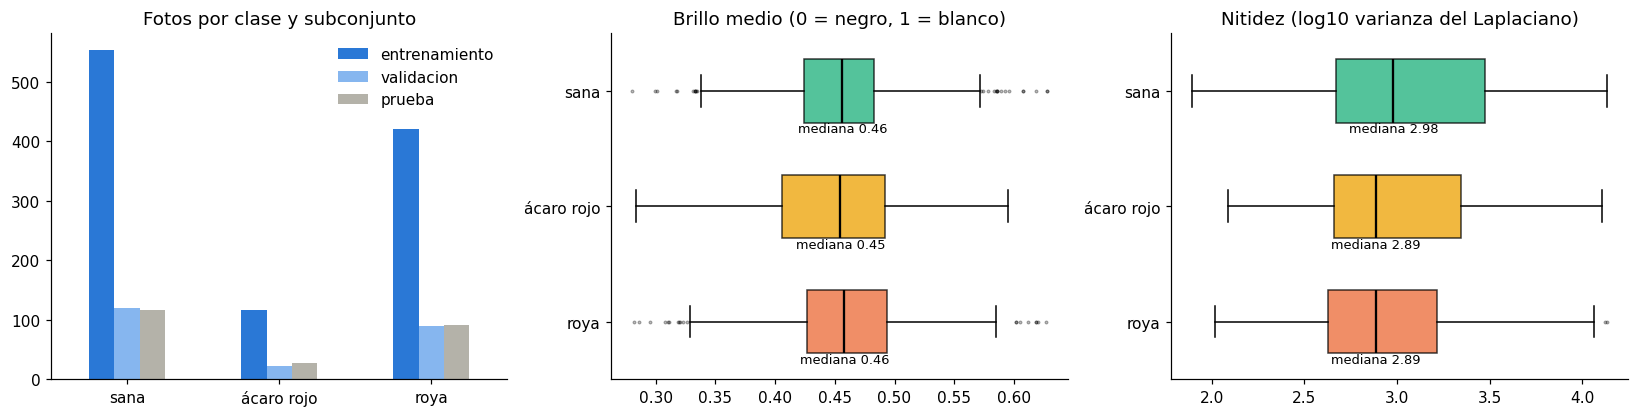

Resoluciones: {'1280x720': 479, '2048x1152': 768, '4128x2322': 313}


In [5]:
def calidad(nombre):
    im = Image.open(RAW / "Photos" / nombre); W, H = im.size
    im.draft("L", (W // 4, H // 4)); g = np.asarray(im.convert("L"), dtype=np.float32)
    lap = g[1:-1, 1:-1] * -4 + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return {"archivo": nombre, "ancho": W, "alto": H, "brillo": g.mean() / 255, "nitidez": lap.var()}

eda_img = tabla.merge(pd.DataFrame([calidad(a) for a in tabla["archivo"]]), on="archivo")
eda_img["log_nitidez"] = np.log10(eda_img["nitidez"])
R2["eda_imagenes"] = {"resoluciones": {f"{a}x{b}": int(n) for (a, b), n in eda_img.groupby(["ancho", "alto"]).size().items()},
                      "mediana_brillo": eda_img.groupby("clase3")["brillo"].median().round(3).to_dict(),
                      "mediana_log_nitidez": eda_img.groupby("clase3")["log_nitidez"].median().round(2).to_dict(),
                      "fotos_nitidez_baja_p5": int((eda_img["nitidez"] < eda_img["nitidez"].quantile(0.05)).sum())}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
conteo[["entrenamiento", "validacion", "prueba"]].plot.bar(ax=axes[0], rot=0, color=["#2a78d6", "#86b6ef", "#b4b2a9"])
axes[0].set_title("Fotos por clase y subconjunto"); axes[0].set_xlabel(""); axes[0].legend(frameon=False)
for ax, col, titulo in ((axes[1], "brillo", "Brillo medio (0 = negro, 1 = blanco)"), (axes[2], "log_nitidez", "Nitidez (log10 varianza del Laplaciano)")):
    datos = [eda_img.loc[eda_img["clase3"] == c, col] for c in CLASES]
    cajas = ax.boxplot(datos, vert=False, patch_artist=True, widths=0.55, tick_labels=CLASES, showfliers=True,
                       flierprops=dict(marker=".", markersize=3, alpha=0.4), medianprops=dict(color="black", lw=1.5))
    for caja, c in zip(cajas["boxes"], CLASES):
        caja.set_facecolor(COLOR[c]); caja.set_alpha(0.75)
    for k, d in enumerate(datos, start=1):
        ax.text(d.median(), k + 0.36, f"mediana {d.median():.2f}", ha="center", fontsize=8.5)
    ax.set_title(titulo); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "a1_eda_imagenes.png", bbox_inches="tight"); plt.show()
print("Resoluciones:", R2["eda_imagenes"]["resoluciones"])

**Ejemplos por clase.** Cinco fotos al azar de cada clase (con semilla fija), completas y sin recortar, para ver el ruido visual real.

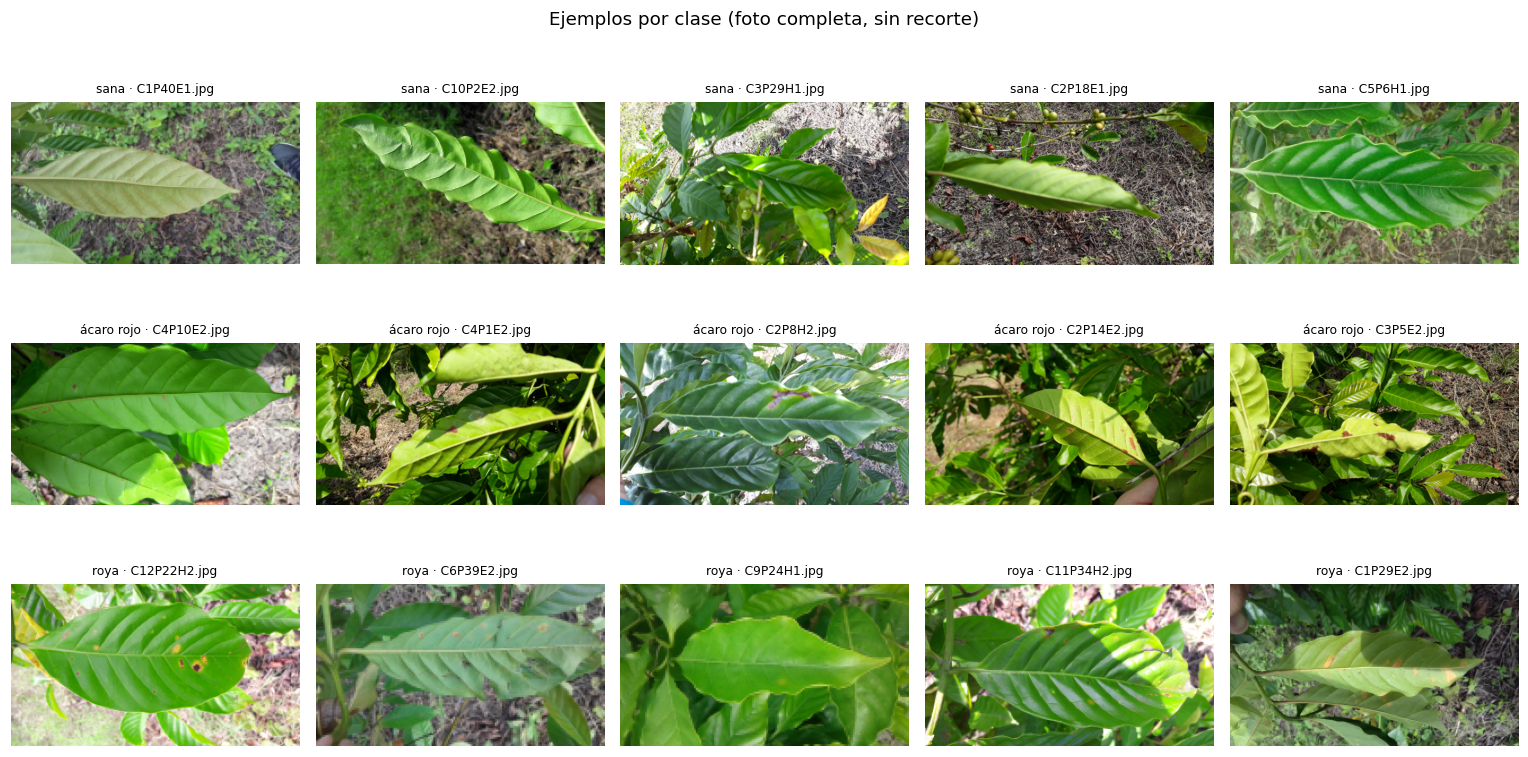

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(14, 7.5))
for fila, c in enumerate(CLASES):
    for col, a in enumerate(tabla[tabla["clase3"] == c].sample(5, random_state=SEMILLA)["archivo"]):
        im = Image.open(RAW / "Photos" / a); im.draft("RGB", (im.width // 8, im.height // 8))
        axes[fila, col].imshow(im.convert("RGB")); axes[fila, col].axis("off")
        axes[fila, col].set_title(f"{c} · {a}", fontsize=8)
fig.suptitle("Ejemplos por clase (foto completa, sin recorte)"); fig.tight_layout()
fig.savefig(FIG / "a1_ejemplos.png", bbox_inches="tight"); plt.show()

**Lectura del EDA de imágenes.**
- **Desbalance:** el ácaro rojo es la clase minoritaria (167 fotos, 11 %). Se compensa con pesos de clase en la pérdida (explicado en A2) y se evalúa con F1 macro, que da el mismo peso a cada clase.
- **Calidad:** las cajas de brillo y nitidez de las tres clases se **solapan casi por completo**, con medianas muy parecidas. Ninguna clase está asociada a fotos más oscuras o más borrosas, así que el modelo no tiene un atajo de calidad.
- **Las fotos poco nítidas se conservan:** el 5 % menos nítido no se descarta, porque en campo el técnico también tomará fotos imperfectas.
- **Variabilidad de captura:** hay 3 resoluciones y 4 celulares, con luz de días soleados, nublados y con viento. Esto justifica el *augmentation* de brillo y contraste.
- **Ruido visual y oclusiones:** el fondo está lleno de otras hojas, algunas enfermas, y a veces aparecen dedos.
  - **Decisión:** la CNN recibe la hoja **recortada** con su caja anotada.
  - **Limitación para el campo:** en uso real hará falta un protocolo de foto centrada en una hoja, o un detector en la Fase 3.

## A2 · Preprocesamiento: recorte, tamaños y *data augmentation*
**Qué hace este bloque:**
1. **Recorta cada hoja** con la caja de su polígono más un margen del 10 %. La rellena con negro hasta hacerla **cuadrada**, para no deformarla (las hojas son alargadas), y la guarda en **256 × 256 px** en `data/processed/fase2/hojas_256/`. Así no hay que decodificar en cada época las fotos originales, de hasta 4128 × 2322 px.
2. **Define dos transformaciones:**
   - **Entrenamiento** (`T_ENTRENO`):
     - recorte aleatorio del 75 % al 100 % del área, redimensionado a 224 px;
     - volteo horizontal y vertical;
     - rotación de hasta ±25°;
     - cambios de brillo, contraste y saturación.
   - **Validación y prueba** (`T_EVAL`): solo redimensiona de 256 a 224 px, sin azar.
3. **Normaliza** con la media y desviación de ImageNet, las mismas con que se entrenaron las redes preentrenadas.
4. **Calcula los pesos de clase** para la pérdida.

**¿Por qué 256 en la caché y 224 en el modelo?**
- **224 × 224** es el tamaño de entrada con que se preentrenaron ResNet50 y EfficientNet-B0 en ImageNet. Usar el mismo tamaño aprovecha mejor lo que ya aprendieron.
- Se guarda en **256** para tener margen. En entrenamiento, el recorte aleatorio toma una parte de la imagen de 256 y la lleva a 224, así que casi nunca hay que *ampliar* la imagen, lo que agregaría borrosidad. Es la convención estándar de ImageNet: redimensionar a 256 y recortar a 224.
- **En validación y prueba no hay azar:** se redimensiona la hoja completa de 256 a 224. La evaluación debe ser **reproducible** (la misma foto da siempre la misma predicción) y debe ver la **hoja entera**; un recorte aleatorio podría dejar fuera justo la lesión.

**¿Por qué pesos de clase iguales al inverso de la frecuencia?**
- **El problema:** sin pesos, la pérdida suma los errores de todas las fotos por igual. Como el ácaro es solo el 11 % del entrenamiento (117 de 1.092 fotos), la red podría casi ignorarlo y aun así tener una pérdida baja.
- **La fórmula:** $w_c = \dfrac{N}{K \cdot n_c}$, con $N$ = fotos de entrenamiento, $K$ = 3 clases y $n_c$ = fotos de la clase $c$.
  - Cada clase termina aportando lo mismo al total: $w_c \cdot n_c = N/K$.
  - Una clase con la frecuencia "justa" (1/3) tendría peso 1.
  - El ácaro queda con un peso cercano a 3: equivocarse en un ácaro cuesta unas 3 veces más que en una sana.
- **Alternativas descartadas:**
  - *Sobremuestreo* (repetir fotos de ácaro): duplicaría imágenes, justo el problema de duplicados que se quiere controlar.
  - *Focal loss*: agrega un hiperparámetro más sin ganancia clara con 3 clases.

In [7]:
DIR_HOJAS = CACHE / "hojas_256"; DIR_HOJAS.mkdir(exist_ok=True)

def recortar_hoja(nombre, margen=0.10, lado=256):
    im = Image.open(RAW / "Photos" / nombre); W, H = im.size
    im.draft("RGB", (W // 2, H // 2)); im = im.convert("RGB"); sx, sy = im.width / W, im.height / H
    xs = [p["x"] * sx for p in poligono[nombre]]; ys = [p["y"] * sy for p in poligono[nombre]]
    mx, my = (max(xs) - min(xs)) * margen, (max(ys) - min(ys)) * margen
    caja = (int(max(0, min(xs) - mx)), int(max(0, min(ys) - my)), int(min(im.width, max(xs) + mx)), int(min(im.height, max(ys) + my)))
    hoja = im.crop(caja); L = max(hoja.size)
    lienzo = Image.new("RGB", (L, L)); lienzo.paste(hoja, ((L - hoja.width) // 2, (L - hoja.height) // 2))
    return lienzo.resize((lado, lado), Image.BILINEAR)

faltan = [a for a in tabla["archivo"] if not (DIR_HOJAS / a).exists()]
for a in faltan:
    recortar_hoja(a).save(DIR_HOJAS / a, quality=95)
print("Hojas recortadas nuevas:", len(faltan), "| en caché:", len(list(DIR_HOJAS.glob("*.jpg"))))

MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
T_ENTRENO = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.3, contrast=0.2, saturation=0.1),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
T_EVAL = transforms.Compose([transforms.Resize(224), transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])

class Hojas(Dataset):
    """Devuelve (imagen transformada, clase 0/1/2) leyendo la hoja recortada de la caché."""
    def __init__(self, df, transform):
        self.archivos, self.y, self.t = df["archivo"].values, df["y3"].values, transform
    def __len__(self):
        return len(self.archivos)
    def __getitem__(self, i):
        return self.t(Image.open(DIR_HOJAS / self.archivos[i]).convert("RGB")), int(self.y[i])

split = {s: tabla[tabla["subconjunto"] == s].reset_index(drop=True) for s in ("entrenamiento", "validacion", "prueba")}
for s, d in split.items():
    d.attrs["split"] = s
n_c = split["entrenamiento"]["y3"].value_counts().sort_index().values
PESOS_CLASE = torch.tensor(n_c.sum() / (len(n_c) * n_c), dtype=torch.float32)
R2["pesos_clase"] = dict(zip(CLASES, PESOS_CLASE.numpy().round(3).tolist()))
print("Fotos de entrenamiento por clase:", dict(zip(CLASES, n_c)), "→ pesos w_c = N/(K·n_c):", R2["pesos_clase"])

Hojas recortadas nuevas: 0 | en caché: 1560
Fotos de entrenamiento por clase: {'sana': 554, 'ácaro rojo': 117, 'roya': 421} → pesos w_c = N/(K·n_c): {'sana': 0.6570000052452087, 'ácaro rojo': 3.1110000610351562, 'roya': 0.8650000095367432}


**Ejemplo de *augmentation*:** la misma hoja de entrenamiento en su versión original y en cinco variantes aleatorias. Así se "ven" las variaciones que el modelo recibe en cada época.

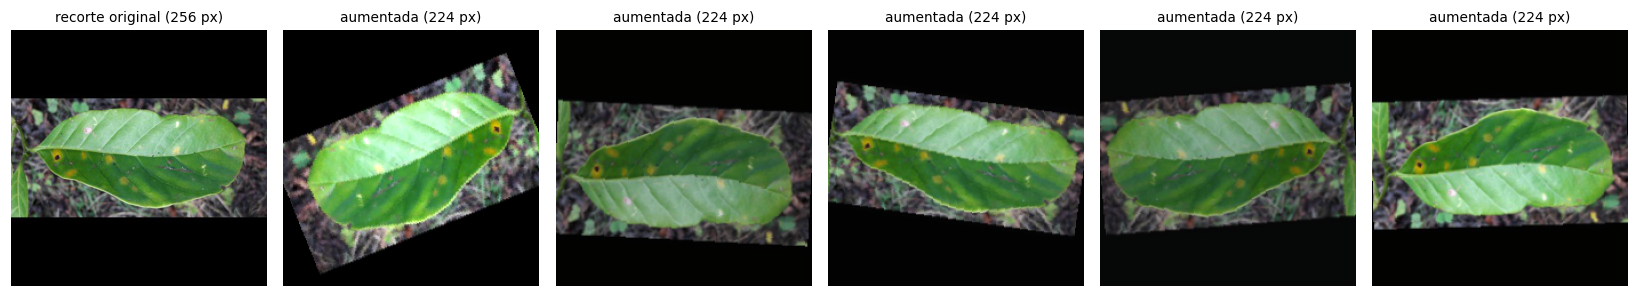

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
ejemplo = Image.open(DIR_HOJAS / split["entrenamiento"]["archivo"][3]).convert("RGB")
axes[0].imshow(ejemplo); axes[0].set_title("recorte original (256 px)", fontsize=9)
torch.manual_seed(SEMILLA)
for ax in axes[1:]:
    x = T_ENTRENO(ejemplo).permute(1, 2, 0).numpy() * DESV + MEDIA
    ax.imshow(np.clip(x, 0, 1)); ax.set_title("aumentada (224 px)", fontsize=9)
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "a2_augmentation.png", bbox_inches="tight"); plt.show()

## A3 · Selección de arquitectura y estrategia de *transfer learning*
### ¿Por qué ResNet50 y EfficientNet-B0?
La actividad sugiere comparar al menos dos redes entre ResNet50, VGG16 y EfficientNet:
- **ResNet50** (He et al., 2016) es la **referencia clásica**. Sus conexiones residuales (atajos que suman la entrada de un bloque a su salida) permiten entrenar redes profundas sin que el gradiente se pierda. Es la línea base contra la que se comparan casi todas las CNN modernas.
- **EfficientNet-B0** (Tan y Le, 2019) es la **alternativa eficiente**: escala de forma equilibrada la profundidad, el ancho y la resolución, y logra una exactitud cercana con **unas 6 veces menos parámetros**. Importa porque la **Fase 3** debe correr la rama visual sin internet en una tableta.
- **VGG16 se descartó:** tiene unos 138 millones de parámetros (casi 6 veces ResNet50), no usa normalización por lotes y es mucho más lenta. No aporta nada que las otras dos no cubran.

### *Feature extraction* frente a *fine-tuning*, en este proyecto
Una red preentrenada en ImageNet ya sabe detectar bordes, texturas, colores y formas. La pregunta es cuánto se le deja **reaprender** con nuestras 1.092 fotos de hojas:

| | *Feature extraction* (FE) | *Fine-tuning* (FT) |
|---|---|---|
| ¿Qué se entrena? | **Solo una capa nueva** al final (de 2.048 o 1.280 entradas a 3 clases). La red queda **congelada** | La capa nueva **y los últimos bloques** de la red, con una tasa de aprendizaje pequeña |
| Analogía | Un experto en fotografía que describe la hoja con su vocabulario; nosotros solo aprendemos a traducir esa descripción a "sana / ácaro / roya" | El mismo experto, pero además **ajusta un poco su vocabulario** para notar detalles de lesiones de café que nunca vio en ImageNet |
| Ventaja | Rápido y con poco riesgo de sobreajuste: entrena muy pocos parámetros | Puede captar rasgos específicos de la lesión |
| Riesgo | Si ImageNet no tiene esos detalles, el techo es bajo | Con pocos datos puede **memorizar** |
| En el código | La red procesa cada foto **una sola vez** y se guarda su vector de rasgos; luego se entrena una capa sobre esos vectores | La foto pasa por toda la red en **cada época**, con *augmentation* en línea |

**Por qué se prueban las dos:**
- El conjunto es **pequeño** (1.092 fotos), lo que favorece FE.
- Es **moderadamente parecido** a ImageNet: fotos naturales con plantas, pero sin pústulas de roya ni bronceado por ácaro, lo que favorece FT.
- No hay una respuesta obvia, así que se decide **con evidencia**:
  1. FE con ambas redes.
  2. FT parcial con la más eficiente.
  3. Comparación de las tres en validación.

### ¿Cómo se mide? F1 macro en validación
- Para cada clase se calcula el **F1**, la media armónica entre precisión (de las que predije como roya, cuántas eran roya) y *recall* (de las roya reales, cuántas encontré).
- El **F1 macro** es el **promedio simple de los 3 F1**, así que el ácaro pesa lo mismo que la clase sana aunque tenga muchas menos fotos.
- Se calcula sobre las **232 fotos de validación**. La prueba no se toca hasta A5.

**Qué hace el bloque siguiente:** carga las dos redes preentrenadas y mide sus parámetros, número de capas convolucionales, milisegundos por imagen en esta máquina, tamaño en disco y exactitud top-1 en ImageNet (dato publicado por torchvision).

In [9]:
def red_base(nombre):
    """Red preentrenada sin su capa final: devuelve (red, tamaño del vector de rasgos, pesos)."""
    if nombre == "resnet50":
        pesos = models.ResNet50_Weights.DEFAULT; m = models.resnet50(weights=pesos); dim = m.fc.in_features; m.fc = nn.Identity()
    else:
        pesos = models.EfficientNet_B0_Weights.DEFAULT; m = models.efficientnet_b0(weights=pesos)
        dim = m.classifier[1].in_features; m.classifier = nn.Identity()
    return m, dim, pesos

ficha = []
for nombre in ("resnet50", "efficientnet_b0"):
    m, dim, pesos = red_base(nombre); m.eval()
    x = torch.randn(32, 3, 224, 224)
    with torch.no_grad():
        m(x[:4]); t0 = time.time(); m(x); seg = (time.time() - t0) / 32
    ficha.append({"arquitectura": nombre, "parametros_M": sum(p.numel() for p in m.parameters()) / 1e6,
                  "capas_conv": sum(isinstance(c, nn.Conv2d) for c in m.modules()), "dim_rasgos": dim,
                  "ms_por_imagen_cpu": seg * 1000, "imagenet_top1": pesos.meta["_metrics"]["ImageNet-1K"]["acc@1"],
                  "tamano_MB": sum(p.numel() for p in m.parameters()) * 4 / 1e6})
ficha = pd.DataFrame(ficha).set_index("arquitectura")
R2["a3_ficha_arquitecturas"] = ficha.round(2).to_dict(orient="index")
ver_tabla(ficha.round(2))

| arquitectura    |   parametros_M |   capas_conv |   dim_rasgos |   ms_por_imagen_cpu |   imagenet_top1 |   tamano_MB |
|:----------------|---------------:|-------------:|-------------:|--------------------:|----------------:|------------:|
| resnet50        |         23.510 |       53 |     2048 |              68.420 |          80.860 |      94.030 |
| efficientnet_b0 |          4.010 |       81 |     1280 |              34.630 |          77.690 |      16.030 |

### *Feature extraction*: extraer y guardar los rasgos
**Qué hace este bloque:**
1. Pasa cada foto por la red **congelada** y guarda el vector de rasgos (2.048 números en ResNet50, 1.280 en EfficientNet-B0) en un archivo `.npz` de caché.
2. Para **entrenamiento** guarda **3 vistas** por foto: la original y 2 aumentadas. Es la forma de aplicar *data augmentation* cuando la red está congelada, porque cada vista da un vector de rasgos distinto.
3. Para **validación y prueba** guarda 1 vista sin azar.

En CPU tarda unos 5 minutos con ResNet50 y unos 2 con EfficientNet-B0. Si la caché existe, se lee directamente.

In [10]:
def extraer_rasgos(nombre, df, transform, vistas=1, semilla=SEMILLA):
    ruta = CACHE / f"rasgos_{nombre}_{df.attrs['split']}_{vistas}v.npz"
    if ruta.exists():
        z = np.load(ruta); return z["X"], z["y"]
    m, dim, _ = red_base(nombre); m.eval()
    X, Y = [], []
    torch.manual_seed(semilla)
    for v in range(vistas):
        cargador = DataLoader(Hojas(df, transform if v > 0 else T_EVAL), batch_size=32, shuffle=False)
        with torch.no_grad():
            for xb, yb in cargador:
                X.append(m(xb).numpy()); Y.append(yb.numpy())
    X, Y = np.concatenate(X), np.concatenate(Y)
    np.savez_compressed(ruta, X=X, y=Y)
    return X, Y

rasgos = {}
for nombre in ("resnet50", "efficientnet_b0"):
    t0 = time.time()
    rasgos[nombre] = {"entrenamiento": extraer_rasgos(nombre, split["entrenamiento"], T_ENTRENO, vistas=3),
                      "validacion": extraer_rasgos(nombre, split["validacion"], T_EVAL),
                      "prueba": extraer_rasgos(nombre, split["prueba"], T_EVAL)}
    print(f"{nombre}: rasgos de entrenamiento {rasgos[nombre]['entrenamiento'][0].shape} (3 vistas) en {time.time() - t0:.0f} s")

resnet50: rasgos de entrenamiento (3276, 2048) (3 vistas) en 0 s
efficientnet_b0: rasgos de entrenamiento (3276, 1280) (3 vistas) en 0 s


### *Feature extraction*: entrenar la capa nueva de 3 clases
**¿Es correcto usar entropía cruzada con 3 clases?** Sí.
- La **entropía cruzada categórica** (`nn.CrossEntropyLoss`) es la generalización directa de la BCE que se usó en la Fase 1.
- La red entrega 3 números (*logits*); `CrossEntropyLoss` les aplica internamente un **softmax**, que los convierte en 3 probabilidades que suman 1, y castiga $-\log p_{\text{clase real}}$. Con 2 clases y sigmoide, es exactamente la BCE.
- Igual que en la Fase 1, el modelo **no lleva softmax dentro** (evita el "doble softmax"), y el softmax se aplica solo al evaluar.
- Lleva los **pesos de clase** de A2.

**Qué hace el bloque:**
- **Normalización:** estandariza los rasgos con la media y la desviación de entrenamiento.
- **Cabeza:** entrena una capa `Dropout(0,3) → Linear(rasgos → 3)` con Adam (lr 10⁻³), lotes de 64 y una pequeña penalización L2.
- **Parada temprana:** vigila la pérdida de validación, con paciencia de 15 épocas.
- **Métricas:** al final calcula, en **validación**, el F1 macro, la exactitud y el *recall* y F1 de cada clase.

In [11]:
def entrenar_cabeza(Xtr, ytr, Xva, yva, epocas=300, paciencia=15, lr=1e-3):
    """Capa de clasificación nueva (3 clases) sobre rasgos congelados. Bucle explícito y parada temprana."""
    fijar_semillas()
    media, desv = Xtr.mean(0), Xtr.std(0) + 1e-6
    Xtr_t = torch.tensor((Xtr - media) / desv, dtype=torch.float32); ytr_t = torch.tensor(ytr)
    Xva_t = torch.tensor((Xva - media) / desv, dtype=torch.float32); yva_t = torch.tensor(yva)
    cabeza = nn.Sequential(nn.Dropout(0.3), nn.Linear(Xtr.shape[1], 3))
    criterio = nn.CrossEntropyLoss(weight=PESOS_CLASE)                 # softmax + log-verosimilitud, con pesos de clase
    optim = torch.optim.Adam(cabeza.parameters(), lr=lr, weight_decay=1e-4)
    cargador = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    mejor, sin_mejora, hist = (math.inf, None, 0), 0, []
    for epoca in range(1, epocas + 1):
        cabeza.train()
        for xb, yb in cargador:
            perdida = criterio(cabeza(xb), yb); optim.zero_grad(); perdida.backward(); optim.step()
        cabeza.eval()
        with torch.no_grad():
            pv = criterio(cabeza(Xva_t), yva_t).item()
        hist.append(pv)
        if pv < mejor[0] - 1e-4:
            mejor, sin_mejora = (pv, copy.deepcopy(cabeza.state_dict()), epoca), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    cabeza.load_state_dict(mejor[1])
    return cabeza, (media, desv), mejor[2], hist

def metricas3(y, prob):
    """Métricas de 3 clases a partir de las probabilidades (la clase predicha es la de mayor probabilidad)."""
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    return {"f1_macro": f1_score(y, pred, average="macro"), "exactitud": accuracy_score(y, pred),
            **{f"recall_{c}": r[i] for i, c in enumerate(CLASES)}, **{f"f1_{c}": f[i] for i, c in enumerate(CLASES)}}

comparacion_fe, cabezas_fe = [], {}
for nombre in ("resnet50", "efficientnet_b0"):
    (Xtr, ytr), (Xva, yva) = rasgos[nombre]["entrenamiento"], rasgos[nombre]["validacion"]
    t0 = time.time(); cabeza, norm, ep, _ = entrenar_cabeza(Xtr, ytr, Xva, yva)
    cabezas_fe[nombre] = (cabeza, norm)
    with torch.no_grad():
        prob = F.softmax(cabeza(torch.tensor((Xva - norm[0]) / norm[1], dtype=torch.float32)), 1).numpy()
    comparacion_fe.append({"arquitectura": nombre, "estrategia": "feature extraction", "mejor_epoca": ep,
                           "seg_entrenamiento": time.time() - t0, **metricas3(yva, prob)})
comparacion_fe = pd.DataFrame(comparacion_fe).set_index("arquitectura")
R2["a3_feature_extraction_validacion"] = comparacion_fe.round(4).to_dict(orient="index")
ver_tabla(comparacion_fe[["estrategia", "mejor_epoca", "f1_macro", "exactitud", "f1_sana", "f1_ácaro rojo", "f1_roya"]].round(3))

| arquitectura    | estrategia         |   mejor_epoca |   f1_macro |   exactitud |   f1_sana |   f1_ácaro rojo |   f1_roya |
|:----------------|:-------------------|--------------:|-----------:|------------:|----------:|----------------:|----------:|
| resnet50        | feature extraction |             9 |      0.665 |       0.763 |     0.874 |           0.393 |     0.729 |
| efficientnet_b0 | feature extraction |             4 |      0.647 |       0.720 |     0.852 |           0.455 |     0.634 |

**Lectura.** La tabla muestra, para cada red congelada, el F1 macro y el F1 de cada clase en **validación**.
- **ResNet50 rinde algo mejor** (F1 macro 0,665 frente a 0,647).
- En ambas, el **ácaro rojo es la clase más difícil**: su F1 es el más bajo.

Aun así, el *fine-tuning* se hace sobre **EfficientNet-B0**:
1. La diferencia en *feature extraction* es pequeña.
2. Tiene casi **6 veces menos parámetros** (4,0 M frente a 23,5 M) y es más del **doble de rápida** en CPU.
3. Ocupa 16 MB frente a 94 MB, lo que la hace la candidata para la tableta de la Fase 3.

Que su *fine-tuning* supere o no a ResNet50 congelada se decide en A4.

## A4 · *Fine-tuning* parcial de EfficientNet-B0
**Qué hace este bloque:**
1. **Construye la red:** una EfficientNet-B0 preentrenada con una capa final nueva `Dropout(0,3) → Linear(1.280 → 3)`.
2. **Congela los bloques 0 a 5** (bordes, colores y texturas genéricas, que sirven igual para hojas) y **descongela los bloques 6, 7 y 8** (formas complejas, los más específicos de ImageNet). Reentrenar toda la red con 1.092 fotos la haría memorizar.
3. **Tasas de aprendizaje distintas:**
   - **10⁻⁴** para los bloques descongelados: solo se ajusta un poco lo que ya saben.
   - **10⁻³** para la capa nueva, que parte de cero.
4. **Entrena** con *augmentation* en línea (cada época ve variantes distintas de cada hoja), entropía cruzada con pesos de clase y lotes de 32. El bucle es explícito: forward → pérdida → `zero_grad` → `backward` → `step`.
5. **Parada temprana:** al final de cada época mide la pérdida y el F1 macro de **validación**. Se detiene si la pérdida no mejora en 4 épocas, y guarda un *checkpoint* con el mejor estado.
6. Si el *checkpoint* ya existe (`RECALCULAR_FT = False`), lo carga en lugar de reentrenar. Tarda unos 15 minutos en CPU.

Durante el entrenamiento, los bloques congelados se dejan en modo evaluación (`modo_entrenamiento`): así sus estadísticas de normalización por lotes (BatchNorm), aprendidas en ImageNet, no se alteran.

In [12]:
def construir_effnet_ft():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 3))
    for p in m.parameters():
        p.requires_grad = False
    for bloque in m.features[6:]:
        for p in bloque.parameters():
            p.requires_grad = True
    for p in m.classifier.parameters():
        p.requires_grad = True
    return m

def modo_entrenamiento(m):
    m.train()
    for bloque in m.features[:6]:          # los bloques congelados mantienen sus estadísticas de BatchNorm
        bloque.eval()

def predecir(m, df, batch=64):
    """Probabilidades de 3 clases (softmax) para todas las fotos de un subconjunto, sin augmentation."""
    m.eval(); P = []
    with torch.no_grad():
        for xb, _ in DataLoader(Hojas(df, T_EVAL), batch_size=batch):
            P.append(F.softmax(m(xb.to(DISPOSITIVO)), 1).cpu().numpy())
    return np.concatenate(P)

RUTA_FT = MODELOS / "rama_a_efficientnet_b0_ft.pth"
RECALCULAR_FT = False
fijar_semillas()
modelo_ft = construir_effnet_ft().to(DISPOSITIVO)
if RUTA_FT.exists() and not RECALCULAR_FT:
    ck = torch.load(RUTA_FT, map_location=DISPOSITIVO, weights_only=False); modelo_ft.load_state_dict(ck["modelo"]); hist_ft = ck["historia"]
    print("Pesos fine-tuning cargados de", RUTA_FT.name, "| mejor época:", ck["mejor_epoca"])
else:
    criterio = nn.CrossEntropyLoss(weight=PESOS_CLASE.to(DISPOSITIVO))
    optim = torch.optim.Adam([{"params": [p for b in modelo_ft.features[6:] for p in b.parameters()], "lr": 1e-4},
                              {"params": modelo_ft.classifier.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    cargador = DataLoader(Hojas(split["entrenamiento"], T_ENTRENO), batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMILLA))
    cargador_va = DataLoader(Hojas(split["validacion"], T_EVAL), batch_size=64)
    hist_ft, mejor, sin_mejora = {"train": [], "val": [], "f1_val": []}, (math.inf, None, 0), 0
    for epoca in range(1, 21):
        t0 = time.time(); modo_entrenamiento(modelo_ft); suma = 0
        for xb, yb in cargador:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            perdida = criterio(modelo_ft(xb), yb)       # 1-2. forward + pérdida
            optim.zero_grad(); perdida.backward()        # 3-4. limpiar gradientes + retropropagación
            optim.step(); suma += perdida.item() * len(yb)   # 5. actualizar pesos
        modelo_ft.eval(); pv, P = 0, []
        with torch.no_grad():
            for xb, yb in cargador_va:
                sal = modelo_ft(xb.to(DISPOSITIVO)); pv += criterio(sal, yb.to(DISPOSITIVO)).item() * len(yb)
                P.append(sal.argmax(1).cpu().numpy())
        pv /= len(split["validacion"]); f1v = float(f1_score(split["validacion"]["y3"], np.concatenate(P), average="macro"))
        hist_ft["train"].append(suma / len(split["entrenamiento"])); hist_ft["val"].append(pv); hist_ft["f1_val"].append(f1v)
        print(f"época {epoca:2d} | pérdida train {hist_ft['train'][-1]:.3f} | val {pv:.3f} | F1 macro val {f1v:.3f} | {time.time() - t0:.0f} s")
        if pv < mejor[0] - 1e-4:
            mejor, sin_mejora = (pv, copy.deepcopy(modelo_ft.state_dict()), epoca), 0
            torch.save({"modelo": mejor[1], "mejor_epoca": epoca, "historia": hist_ft, "clases": CLASES,
                        "preproceso": {"lado": 224, "media": MEDIA, "desv": DESV, "recorte": "caja de la hoja + 10 %, relleno a cuadrado"}},
                       RUTA_FT)                                    # checkpoint del mejor estado
        else:
            sin_mejora += 1
            if sin_mejora >= 4:
                break
    modelo_ft.load_state_dict(mejor[1])
    ck = torch.load(RUTA_FT, map_location=DISPOSITIVO, weights_only=False); ck["historia"] = hist_ft
    torch.save(ck, RUTA_FT)                                         # se añade la historia completa (incluye las épocas tras el mínimo)
    print("Mejor época:", mejor[2])

época  1 | pérdida train 0.974 | val 0.771 | F1 macro val 0.635 | 72 s


época  2 | pérdida train 0.720 | val 0.667 | F1 macro val 0.664 | 69 s


época  3 | pérdida train 0.641 | val 0.601 | F1 macro val 0.677 | 70 s


época  4 | pérdida train 0.556 | val 0.627 | F1 macro val 0.646 | 63 s


época  5 | pérdida train 0.480 | val 0.584 | F1 macro val 0.704 | 64 s


época  6 | pérdida train 0.483 | val 0.581 | F1 macro val 0.695 | 76 s


... (3 outputs left out)

época 10 | pérdida train 0.322 | val 0.548 | F1 macro val 0.738 | 65 s


época 11 | pérdida train 0.316 | val 0.572 | F1 macro val 0.726 | 70 s


época 12 | pérdida train 0.298 | val 0.574 | F1 macro val 0.732 | 67 s


época 13 | pérdida train 0.295 | val 0.635 | F1 macro val 0.764 | 65 s
Mejor época: 9


**Comparación final de las tres opciones en validación.** El bloque siguiente:
1. Calcula las métricas en validación del modelo con *fine-tuning*.
2. Las pone junto a las dos redes congeladas en una sola tabla y en un gráfico de barras del F1 macro.
3. Dibuja las curvas de pérdida del *fine-tuning*.
4. Elige el modelo con **mayor F1 macro en validación**. La prueba no interviene en la elección.

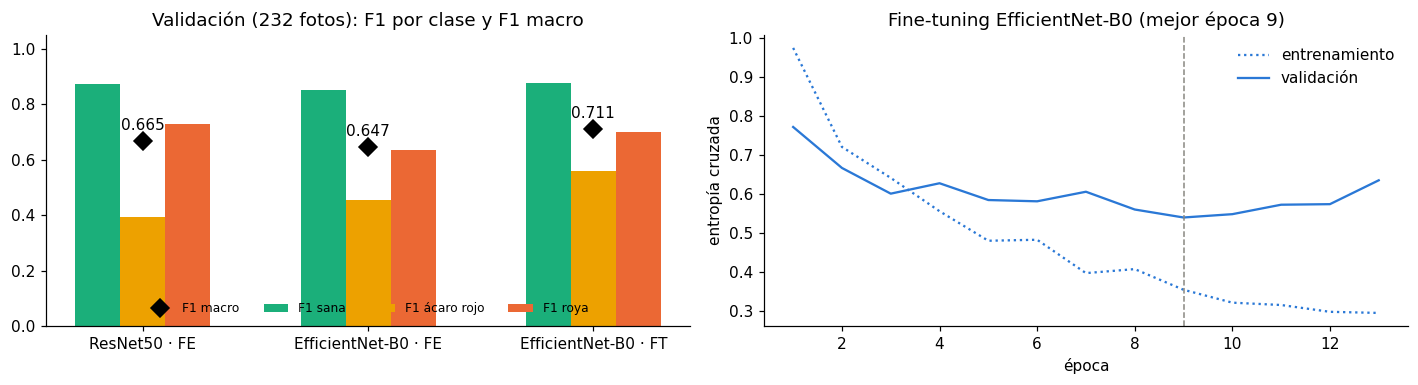

Elegido: EfficientNet-B0 · FT


| modelo               |   mejor_epoca |   f1_macro |   exactitud |   f1_sana |   f1_ácaro rojo |   f1_roya |
|:---------------------|--------------:|-----------:|------------:|----------:|----------------:|----------:|
| ResNet50 · FE        |         9 |      0.665 |       0.763 |     0.874 |           0.393 |     0.729 |
| EfficientNet-B0 · FE |         4 |      0.647 |       0.720 |     0.852 |           0.455 |     0.634 |
| EfficientNet-B0 · FT |         9 |      0.711 |       0.772 |     0.878 |           0.557 |     0.699 |

In [13]:
ck = torch.load(RUTA_FT, map_location=DISPOSITIVO, weights_only=False)
EPOCA_FT = ck["mejor_epoca"]
prob_va_ft = predecir(modelo_ft, split["validacion"])
m_ft = {"arquitectura": "efficientnet_b0", "estrategia": "fine-tuning (bloques 6-8)", "mejor_epoca": EPOCA_FT,
        **metricas3(split["validacion"]["y3"].values, prob_va_ft)}
fe_vs_ft = pd.concat([comparacion_fe.reset_index(), pd.DataFrame([m_ft])], ignore_index=True)
R2["a4_fe_vs_ft_validacion"] = fe_vs_ft.drop(columns="seg_entrenamiento", errors="ignore").round(4).to_dict(orient="records")
etiquetas = ["ResNet50 · FE", "EfficientNet-B0 · FE", "EfficientNet-B0 · FT"]
candidatos = dict(zip(etiquetas, fe_vs_ft["f1_macro"]))
ELEGIDO_A = max(candidatos, key=candidatos.get)
R2["a_modelo_elegido"] = ELEGIDO_A

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
x = np.arange(3); w = 0.2
for k, col in enumerate(["f1_sana", "f1_ácaro rojo", "f1_roya"]):
    axes[0].bar(x + (k - 1) * w, fe_vs_ft[col], w, color=COLOR[CLASES[k]], label=f"F1 {CLASES[k]}")
axes[0].plot(x, fe_vs_ft["f1_macro"], "kD", ms=8, label="F1 macro")
for i, v in enumerate(fe_vs_ft["f1_macro"]):
    axes[0].text(i, v + 0.04, f"{v:.3f}", ha="center", fontsize=10)
axes[0].set_xticks(x, etiquetas); axes[0].set_ylim(0, 1.05); axes[0].legend(frameon=False, ncol=4, fontsize=8, loc="lower center")
axes[0].set_title("Validación (232 fotos): F1 por clase y F1 macro")
ep = range(1, len(hist_ft["train"]) + 1)
axes[1].plot(ep, hist_ft["train"], ls=":", color="#2a78d6", label="entrenamiento"); axes[1].plot(ep, hist_ft["val"], color="#2a78d6", label="validación")
axes[1].axvline(EPOCA_FT, color="#898781", ls="--", lw=1); axes[1].set_xlabel("época"); axes[1].set_ylabel("entropía cruzada")
axes[1].set_title(f"Fine-tuning EfficientNet-B0 (mejor época {EPOCA_FT})"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "a4_curvas_ft.png", bbox_inches="tight"); plt.show()
print("Elegido:", ELEGIDO_A)
ver_tabla(fe_vs_ft.assign(modelo=etiquetas).set_index("modelo")[["mejor_epoca", "f1_macro", "exactitud", "f1_sana", "f1_ácaro rojo", "f1_roya"]].round(3))

**Lectura.**
- El ***fine-tuning* parcial** sube el F1 macro de validación a **0,711**, por encima de ResNet50 congelada (0,665) y de EfficientNet-B0 congelada (0,647).
- Es la **evidencia empírica** de que ajustar los últimos bloques ayuda: la red aprende detalles de las lesiones que ImageNet no tenía.
- La curva muestra que la pérdida de validación toca su mínimo en la **época 9** y luego sube, mientras la de entrenamiento sigue bajando. A partir de ahí la red empieza a memorizar, y la parada temprana conserva la época 9.

**Modelo de la rama A: EfficientNet-B0 con *fine-tuning*.** La función `prob_rama_a` devuelve sus probabilidades para cualquier subconjunto.

In [14]:
def prob_rama_a(df_split):
    """Probabilidades de 3 clases del modelo elegido para un subconjunto."""
    if ELEGIDO_A.endswith("FT"):
        return predecir(modelo_ft, df_split)
    nombre = "resnet50" if ELEGIDO_A.startswith("ResNet") else "efficientnet_b0"
    cabeza, (media, desv) = cabezas_fe[nombre]
    X, _ = rasgos[nombre][df_split.attrs["split"]]
    with torch.no_grad():
        return F.softmax(cabeza(torch.tensor((X - media) / desv, dtype=torch.float32)), 1).numpy()

## A5 · Evaluación en prueba (una sola vez) e interpretabilidad
### Métricas de 3 clases
**Qué hace este bloque:**
1. Obtiene las probabilidades del modelo elegido para las **236 fotos de prueba**. Es la única vez que se usa la prueba en la rama A.
2. Calcula la **matriz de confusión 3×3**: filas = clase real, columnas = clase predicha.
3. Calcula la precisión, el *recall* y el F1 de cada clase.

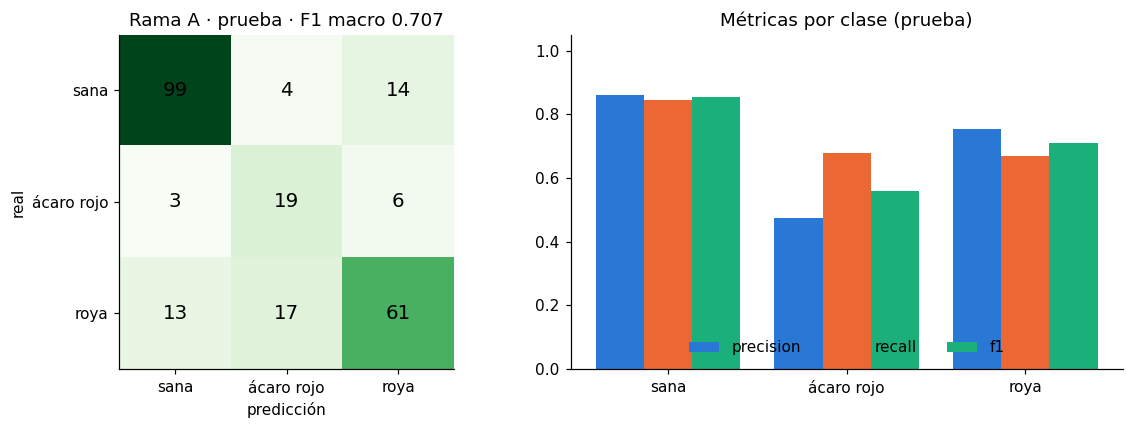

|            |   precision |   recall |    f1 |       n |
|:-----------|------------:|---------:|------:|--------:|
| sana       |       0.861 |    0.846 | 0.853 | 117 |
| ácaro rojo |       0.475 |    0.679 | 0.559 |  28 |
| roya       |       0.753 |    0.670 | 0.709 |  91 |

In [15]:
prob_va_a, prob_te_a = prob_rama_a(split["validacion"]), prob_rama_a(split["prueba"])
y_te3 = split["prueba"]["y3"].values
m3_te = metricas3(y_te3, prob_te_a)
cm3 = confusion_matrix(y_te3, prob_te_a.argmax(1), labels=[0, 1, 2])
p3, r3, f3, s3 = precision_recall_fscore_support(y_te3, prob_te_a.argmax(1), labels=[0, 1, 2], zero_division=0)
tabla_clase = pd.DataFrame({"precision": p3, "recall": r3, "f1": f3, "n": s3}, index=CLASES)
R2["a5_prueba_3clases"] = {"global": {k: round(v, 4) for k, v in m3_te.items()}, "por_clase": tabla_clase.round(4).to_dict(orient="index"),
                           "matriz": cm3.tolist()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(cm3, cmap="Greens")
for (i, j), v in np.ndenumerate(cm3):
    axes[0].text(j, i, v, ha="center", va="center", fontsize=13)
axes[0].set_xticks(range(3), CLASES); axes[0].set_yticks(range(3), CLASES)
axes[0].set_xlabel("predicción"); axes[0].set_ylabel("real"); axes[0].set_title(f"Rama A · prueba · F1 macro {m3_te['f1_macro']:.3f}")
x = np.arange(3); w = 0.27
for k, met in enumerate(["precision", "recall", "f1"]):
    axes[1].bar(x + (k - 1) * w, tabla_clase[met], w, label=met, color=["#2a78d6", "#eb6834", "#1baf7a"][k])
axes[1].set_xticks(x, CLASES); axes[1].set_ylim(0, 1.05); axes[1].legend(frameon=False, ncol=3, loc="lower center")
axes[1].set_title("Métricas por clase (prueba)")
fig.tight_layout(); fig.savefig(FIG / "a5_matriz_metricas.png", bbox_inches="tight"); plt.show()
ver_tabla(tabla_clase.round(3))

### De 3 clases a la alerta sí/no: ¿de dónde sale el umbral?
Para comparar con la Fase 1, las probabilidades se convierten en una **alerta binaria**:
- **Puntaje de alerta** = P(ácaro) + P(roya) = 1 − P(sana).
- Se alerta si el puntaje ≥ umbral.

**El umbral se elige con la MISMA regla de la Fase 1, aplicada al NUEVO modelo:**
1. Se prueban todos los umbrales de 0,01 a 0,99 sobre las fotos de **validación**.
2. Se descartan los que detectan menos del 90 % de las hojas afectadas (*recall* < 0,90).
3. Entre los que quedan, se elige el de **menor costo 5·FN + FP**.

**¿Por qué no da 0,22, como en la Fase 1?** Porque 0,22 era el umbral óptimo para las probabilidades **del MLP**. Cada modelo tiene su propia escala de probabilidades:
- Una CNN entrenada con entropía cruzada y pesos de clase tiende a dar probabilidades más "seguras" (más cerca de 0 o de 1) que el MLP.
- Por eso el punto que minimiza el costo cae en otro lugar.

Copiar 0,22 sería aplicar una calibración ajena. Lo que se conserva es la **regla**, no el número. El bloque siguiente dibuja la curva de costo en validación para que se vea dónde está el mínimo.

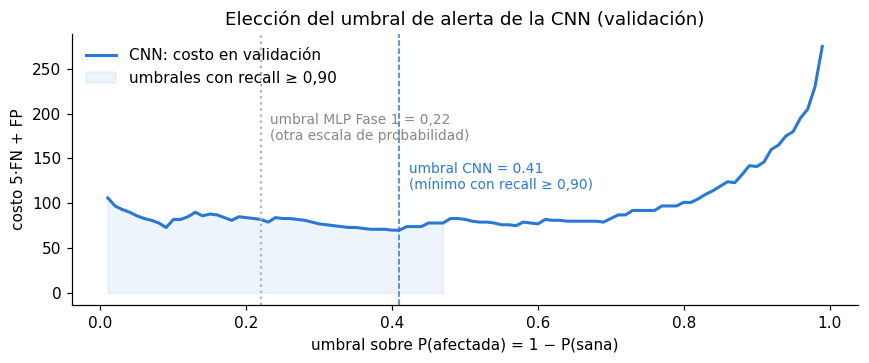

Umbral elegido en validación: 0.41 → PRUEBA: AUC 0.934 | recall 0.899 | FN 12 | FP 29 | costo 89   (MLP Fase 1: AUC 0.936, FN 3, costo 54)


In [16]:
REJILLA = np.round(np.arange(0.01, 1.00, 0.01), 2)
def curva_costo(y, s, rejilla=REJILLA):
    filas = []
    for u in rejilla:
        pred = (s >= u).astype(int); vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        filas.append({"umbral": u, "recall": vp / max(vp + fn, 1), "FN": int(fn), "FP": int(fp), "costo": COSTO_FN * fn + COSTO_FP * fp})
    return pd.DataFrame(filas)

def costo_umbral(y, s, rejilla=REJILLA):
    """Regla de la Fase 1: menor 5·FN + FP entre los umbrales con recall ≥ 0,90 (en validación)."""
    t = curva_costo(y, s, rejilla); c = t[t["recall"] >= RECALL_MIN]
    return float((c if len(c) else t).sort_values(["costo", "umbral"], ascending=[True, False]).iloc[0]["umbral"])

def metricas_bin(y, s, u):
    pred = (s >= u).astype(int); vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {"umbral": u, "auc": roc_auc_score(y, s), "recall": r[1], "precision": p[1], "f1": f[1],
            "VP": int(vp), "FN": int(fn), "FP": int(fp), "VN": int(vn), "costo": int(COSTO_FN * fn + COSTO_FP * fp)}

y_va_bin = split["validacion"]["afectada"].values
curva_a = curva_costo(y_va_bin, 1 - prob_va_a[:, 0])
U_A = costo_umbral(y_va_bin, 1 - prob_va_a[:, 0])
mbin_a = metricas_bin(split["prueba"]["afectada"].values, 1 - prob_te_a[:, 0], U_A)
fase1 = json.loads((ROOT / "resultados" / "resultados.json").read_text(encoding="utf-8"))["prueba"]["mlp"]
R2["a5_prueba_alerta"] = {"cnn": mbin_a, "mlp_fase1": {k: fase1[k] for k in ("auc", "recall_afectada", "precision_afectada", "f1_afectada", "FN", "FP", "costo")},
                          "umbral_fase1": 0.22}

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(curva_a["umbral"], curva_a["costo"], color="#2a78d6", lw=2, label="CNN: costo en validación")
validos = curva_a[curva_a["recall"] >= RECALL_MIN]
ax.fill_between(validos["umbral"], 0, validos["costo"], color="#2a78d6", alpha=0.08, label="umbrales con recall ≥ 0,90")
ax.axvline(U_A, color="#2a78d6", ls="--", lw=1); ax.axvline(0.22, color="#b4b2a9", ls=":", lw=1.5)
ax.annotate(f"umbral CNN = {U_A:.2f}\n(mínimo con recall ≥ 0,90)", (U_A, curva_a["costo"].max() * 0.42), xytext=(6, 0),
            textcoords="offset points", color="#2a78d6", fontsize=9)
ax.annotate("umbral MLP Fase 1 = 0,22\n(otra escala de probabilidad)", (0.22, curva_a["costo"].max() * 0.62), xytext=(6, 0),
            textcoords="offset points", color="#898781", fontsize=9)
ax.set_xlabel("umbral sobre P(afectada) = 1 − P(sana)"); ax.set_ylabel("costo 5·FN + FP"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Elección del umbral de alerta de la CNN (validación)")
fig.tight_layout(); fig.savefig(FIG / "a5_umbral.png", bbox_inches="tight"); plt.show()
print(f"Umbral elegido en validación: {U_A:.2f} → PRUEBA: AUC {mbin_a['auc']:.3f} | recall {mbin_a['recall']:.3f} | "
      f"FN {mbin_a['FN']} | FP {mbin_a['FP']} | costo {mbin_a['costo']}   (MLP Fase 1: AUC {fase1['auc']:.3f}, FN {fase1['FN']:.0f}, costo {fase1['costo']:.0f})")

### Errores más confiados y Grad-CAM
**Qué hace el primer bloque:** muestra las 8 fotos de prueba en que el modelo se equivocó **con más seguridad** (mayor probabilidad en la clase equivocada), con su clase real y la predicha. Ayuda a entender qué confunde al modelo.

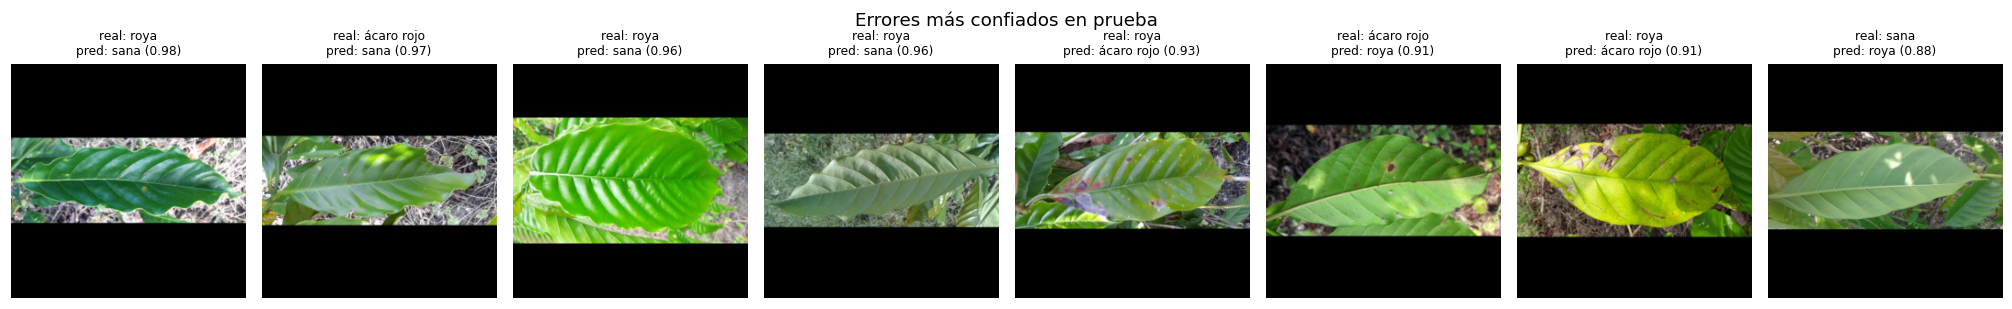

In [17]:
pred_te = prob_te_a.argmax(1); errores = split["prueba"].assign(pred=[CLASES[i] for i in pred_te], conf=prob_te_a.max(1))
errores = errores[errores["pred"] != errores["clase3"]].sort_values("conf", ascending=False).head(8)
fig, axes = plt.subplots(1, max(len(errores), 1), figsize=(2.3 * max(len(errores), 1), 2.9), squeeze=False)
for ax, (_, f) in zip(axes[0], errores.iterrows()):
    ax.imshow(Image.open(DIR_HOJAS / f["archivo"])); ax.axis("off")
    ax.set_title(f"real: {f['clase3']}\npred: {f['pred']} ({f['conf']:.2f})", fontsize=8)
fig.suptitle("Errores más confiados en prueba"); fig.tight_layout(); fig.savefig(FIG / "a5_errores.png", bbox_inches="tight"); plt.show()
R2["a5_errores_mas_confiados"] = {f"{r} → {p}": int(n) for (r, p), n in errores.groupby(["clase3", "pred"]).size().items()}

**Grad-CAM** (Selvaraju et al., 2017) responde **dónde mira la red** para decidir.

**Qué hace el bloque:**
1. Registra las activaciones de la última capa convolucional, un mapa de 7×7 con 1.280 canales.
2. Calcula el gradiente de la clase predicha respecto a esas activaciones.
3. Promedia los gradientes de cada canal para obtener su peso.
4. Suma los mapas ponderados y conserva solo la parte positiva (ReLU).
5. Amplía el mapa a 224×224 y lo superpone a la foto (rojo = más influencia).

Si el modelo es confiable, el rojo debe caer sobre la **hoja** y sus manchas, no sobre el fondo ni los dedos. Se muestran 2 aciertos por clase y 2 errores.

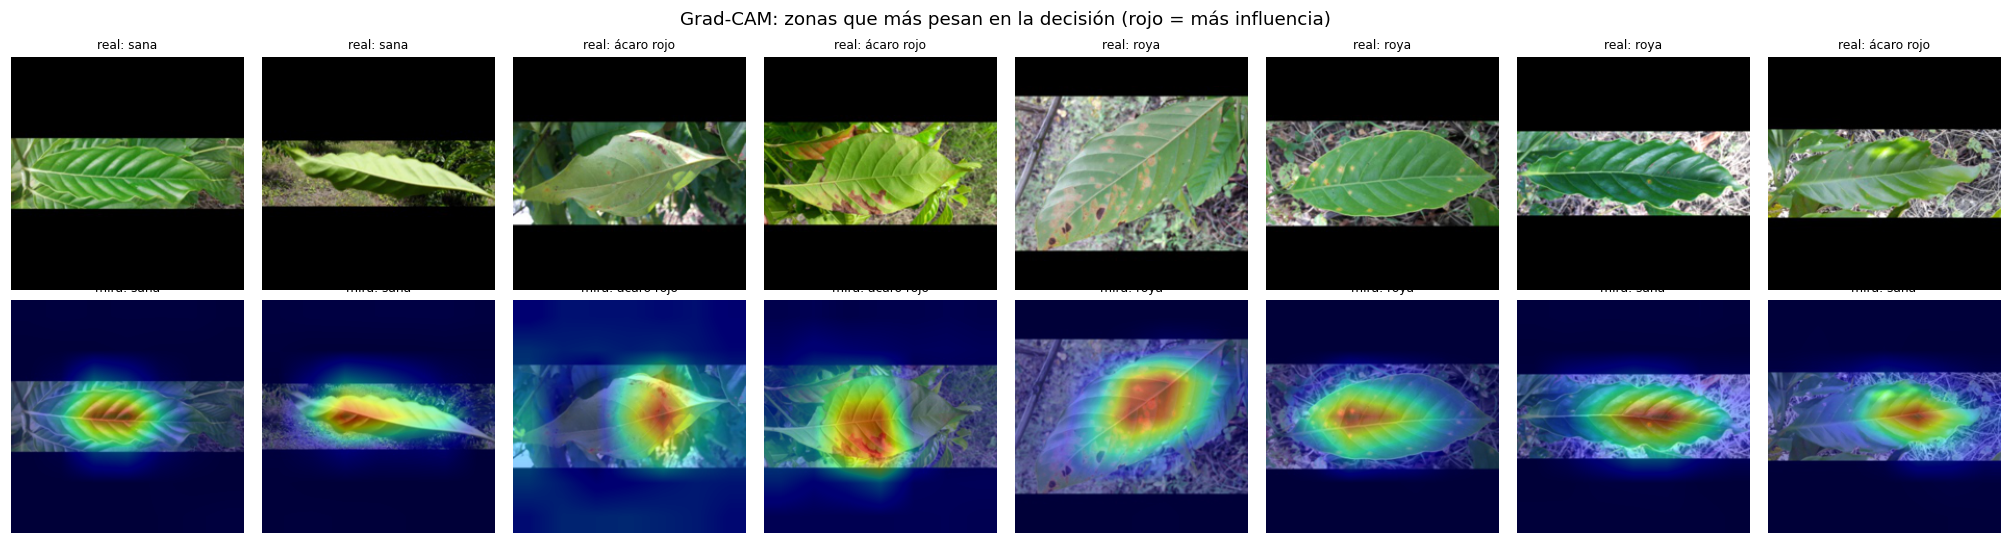

In [18]:
def grad_cam(modelo, x, clase=None):
    """x: tensor (1, 3, 224, 224). Devuelve mapa 224×224 en [0, 1] y la clase explicada (EfficientNet-B0)."""
    capa = modelo.features[-1]; act, grad = {}, {}
    h1 = capa.register_forward_hook(lambda m, i, o: act.update(a=o))
    h2 = capa.register_full_backward_hook(lambda m, gi, go: grad.update(g=go[0]))
    modelo.eval(); x = x.clone().requires_grad_(True)
    salida = modelo(x); clase = int(salida.argmax(1)) if clase is None else clase
    modelo.zero_grad(); salida[0, clase].backward()
    h1.remove(); h2.remove()
    pesos = grad["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((pesos * act["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), clase

modelo_cam = modelo_ft
correctas = split["prueba"].assign(pred=pred_te)
muestras = pd.concat([correctas[(correctas["y3"] == k) & (correctas["pred"] == k)].sample(2, random_state=SEMILLA) for k in range(3)]
                     + [errores.head(2).assign(y3=lambda d: d["clase3"].map({c: i for i, c in enumerate(CLASES)}))])
fig, axes = plt.subplots(2, len(muestras), figsize=(2.3 * len(muestras), 5))
for j, (_, f) in enumerate(muestras.iterrows()):
    im = Image.open(DIR_HOJAS / f["archivo"]).convert("RGB")
    cam, k = grad_cam(modelo_cam, T_EVAL(im).unsqueeze(0))
    base = np.asarray(im.resize((224, 224))) / 255
    axes[0, j].imshow(base); axes[0, j].set_title(f"real: {f['clase3']}", fontsize=8)
    axes[1, j].imshow(base); axes[1, j].imshow(cam, cmap="jet", alpha=0.45); axes[1, j].set_title(f"mira: {CLASES[k]}", fontsize=8)
    for a in axes[:, j]: a.axis("off")
fig.suptitle("Grad-CAM: zonas que más pesan en la decisión (rojo = más influencia)")
fig.tight_layout(); fig.savefig(FIG / "a5_gradcam.png", bbox_inches="tight"); plt.show()

**Lectura de la rama A en prueba.**
- **Métricas:** F1 macro de 0,707 y exactitud de 76 %.
  - Las **sanas** se reconocen bien (F1 0,85).
  - La **roya** se confunde con ácaro y con sana.
  - El **ácaro** es la clase más difícil (precisión 0,48): muchas fotos que el modelo llama ácaro son en realidad roya. Ambas lesiones dejan manchas rojizas, y la roya leve son puntos pequeños que se pierden al reducir la foto a 224 px.
- **Alerta sí/no:** AUC de 0,934, prácticamente igual al MLP de la Fase 1 (0,936), es decir, el mismo poder para ordenar hojas enfermas por encima de sanas. Pero con su umbral de validación (0,41), en prueba deja escapar 12 hojas enfermas frente a 3 del MLP: costo 89 frente a 54.
- **Conclusión honesta:** con 1.092 fotos, **la CNN no supera** a los 27 rasgos de la Fase 1. Esos rasgos codifican directamente el conocimiento agronómico (% de color anaranjado y amarillo), y la CNN tiene que aprenderlo de pocos ejemplos. Su valor agregado es **distinguir ácaro de roya**.
- **Grad-CAM:** la red mira la **lámina de la hoja**, no el fondo ni los dedos, y en las hojas con ácaro se concentra en las zonas rojizas. El mapa es grueso (7×7), así que señala regiones y no pústulas individuales.

# RAMA B · Series temporales (RNN simple, LSTM, GRU)
## B1 · La serie: clima diario de NASA POWER en la finca
**Qué hace este bloque:**
1. Descarga (o lee de `data/external/`, si ya existe) el clima diario de NASA POWER en las coordenadas de CIIDEA, del **2001-01-01 al 2019-05-01**. Esa fecha es el día anterior a la última foto: no se usa ningún dato posterior a las fotos. Las variables son:
   - temperatura a 2 m (`T2M`);
   - humedad relativa (`RH2M`);
   - lluvia (`PRECTOTCORR`);
   - viento (`WS2M`).
2. Reemplaza el código de faltante de NASA (−999) por NaN e interpola los huecos, si los hay.
3. Cuenta los atípicos extremos (|z| > 4).
4. Grafica las 4 series con su media móvil de 30 días.

**Objetivo de la rama B:** pronosticar la **humedad relativa del día siguiente**. La humedad alta y sostenida es la condición que más favorece la germinación de la roya.

{'observaciones': 6695, 'inicio': '2001-01-01', 'fin': '2019-05-01', 'faltantes': 0, 'atipicos_z4': {'T2M': 0, 'RH2M': 0, 'PRECTOTCORR': 91, 'WS2M': 0}, 'media': {'T2M': 26.66, 'RH2M': 69.42, 'PRECTOTCORR': 2.83, 'WS2M': 2.19}}


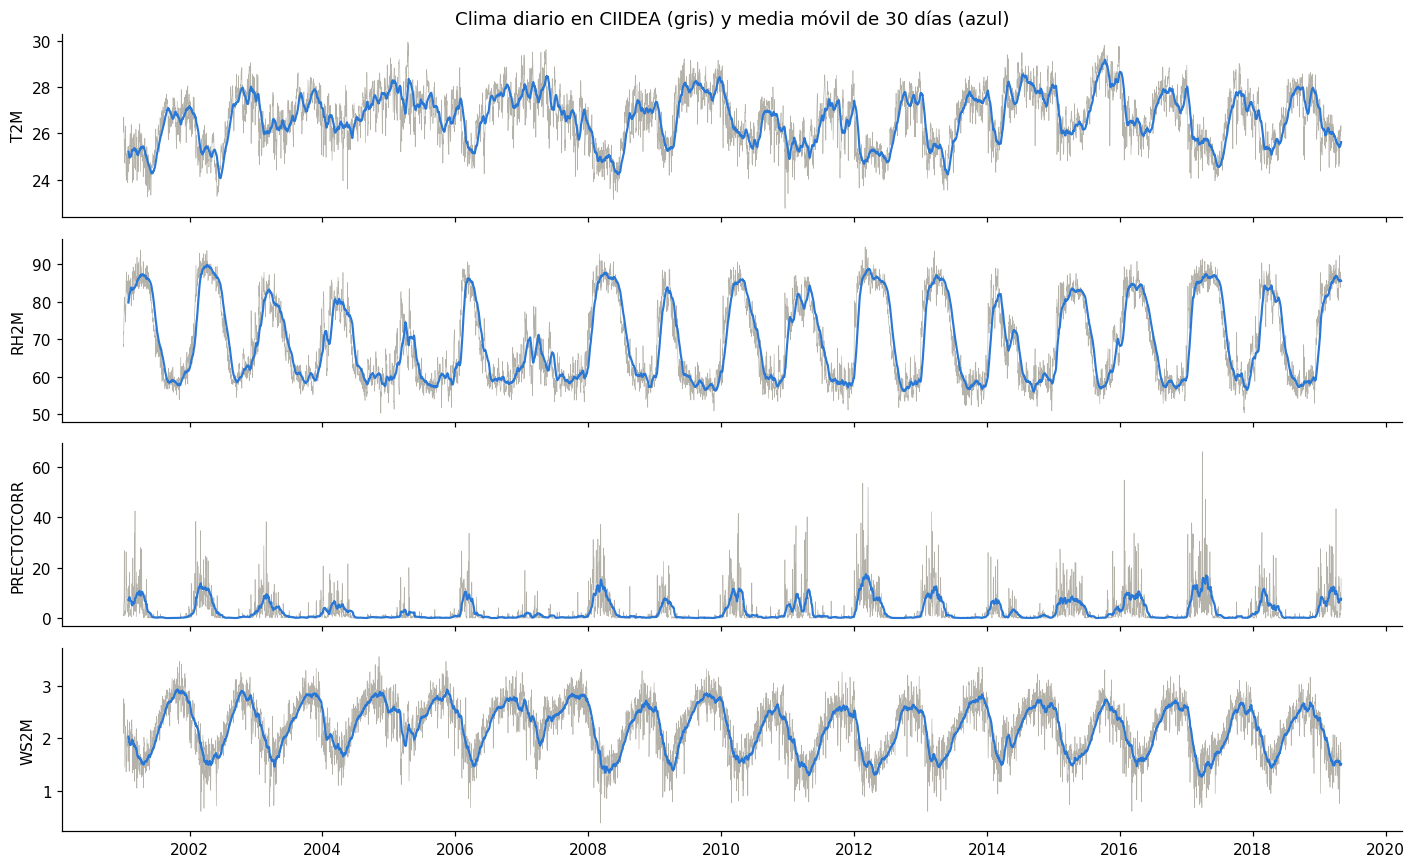

In [19]:
ruta_clima = ROOT / "data" / "external" / "nasa_power_ciidea_2001_2019.csv"
ruta_clima.parent.mkdir(parents=True, exist_ok=True)
if not ruta_clima.exists():
    r = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", timeout=180, params={
        "parameters": "T2M,RH2M,PRECTOTCORR,WS2M", "community": "AG", "latitude": LAT, "longitude": LON,
        "start": "20010101", "end": "20190501", "format": "JSON"})
    p = r.json()["properties"]["parameter"]
    serie = pd.DataFrame(p); serie.index = pd.to_datetime(serie.index, format="%Y%m%d"); serie.index.name = "fecha"
    serie.to_csv(ruta_clima)
serie = pd.read_csv(ruta_clima, index_col="fecha", parse_dates=True).replace(-999, np.nan)
VARS = ["T2M", "RH2M", "PRECTOTCORR", "WS2M"]
faltantes = int(serie[VARS].isna().sum().sum())
serie[VARS] = serie[VARS].interpolate(limit_direction="both")
z = (serie[VARS] - serie[VARS].mean()) / serie[VARS].std()
atipicos = (z.abs() > 4).sum().to_dict()
R2["b1_serie"] = {"observaciones": len(serie), "inicio": str(serie.index.min().date()), "fin": str(serie.index.max().date()),
                  "faltantes": faltantes, "atipicos_z4": {k: int(v) for k, v in atipicos.items()},
                  "media": serie[VARS].mean().round(2).to_dict()}
print(R2["b1_serie"])

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for ax, v in zip(axes, VARS):
    ax.plot(serie.index, serie[v], lw=0.4, color="#b4b2a9")
    ax.plot(serie.index, serie[v].rolling(30).mean(), lw=1.4, color="#2a78d6")
    ax.set_ylabel(v)
axes[0].set_title("Clima diario en CIIDEA (gris) y media móvil de 30 días (azul)")
fig.tight_layout(); fig.savefig(FIG / "b1_serie.png", bbox_inches="tight"); plt.show()

**Estacionalidad y memoria de la humedad.** El bloque dibuja tres gráficos:
- Diagramas de caja de la humedad **por mes**: muestran la estacionalidad anual.
- La **ACF** (autocorrelación) hasta 400 días: cuánto se parece la humedad de hoy a la de hace *k* días.
- La **PACF** (autocorrelación parcial) hasta 40 días: lo mismo, pero descontando los días intermedios, para ver qué rezagos aportan información propia.

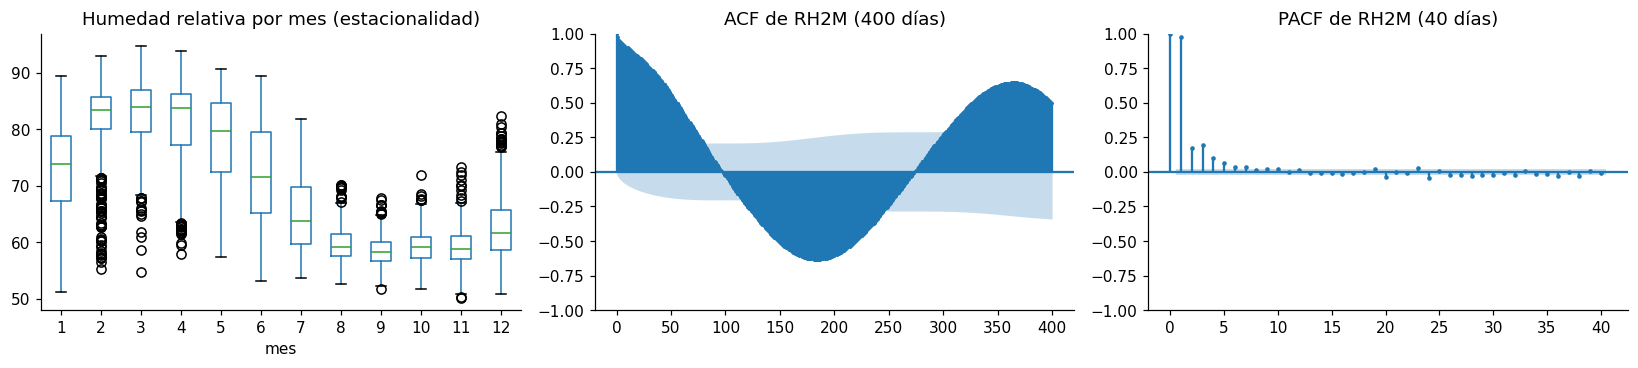

Autocorrelación RH2M: 1 día 0.973 | 365 días 0.693


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
serie.assign(mes=serie.index.month).boxplot(column="RH2M", by="mes", ax=axes[0], grid=False)
axes[0].set_title("Humedad relativa por mes (estacionalidad)"); axes[0].set_xlabel("mes"); fig.suptitle("")
plot_acf(serie["RH2M"], lags=400, ax=axes[1], markersize=1); axes[1].set_title("ACF de RH2M (400 días)")
plot_pacf(serie["RH2M"], lags=40, ax=axes[2], method="ywm", markersize=2); axes[2].set_title("PACF de RH2M (40 días)")
fig.tight_layout(); fig.savefig(FIG / "b1_estacionalidad_acf.png", bbox_inches="tight"); plt.show()
acf_365 = serie["RH2M"].autocorr(365); acf_1 = serie["RH2M"].autocorr(1)
R2["b1_acf"] = {"lag1": round(acf_1, 3), "lag365": round(acf_365, 3)}
print(f"Autocorrelación RH2M: 1 día {acf_1:.3f} | 365 días {acf_365:.3f}")

**Lectura del EDA de la serie.**
- **Estacionalidad anual:** la humedad es más alta en la estación lluviosa (de enero a mayo, en la costa ecuatoriana) y más baja en la seca. Lo confirman el pico de la ACF cerca de los 365 días (0,69) y las cajas por mes.
- **Memoria corta muy fuerte:** la autocorrelación a 1 día es de 0,97, así que "mañana igual que hoy" (persistencia) es una línea base exigente. La PACF indica que, descontado el día anterior, solo los primeros rezagos aportan.
- **Calidad:** no hay faltantes. Los atípicos de lluvia son tormentas reales y se conservan.

**¿Por qué una red recurrente y no solo ARIMA?**
- ARIMA es **lineal** y **univariado**.
- La humedad de mañana depende de forma no lineal de la temperatura, la lluvia y el viento de varios días atrás.
- Una red recurrente procesa las 4 variables a la vez y puede aprender esas interacciones.
- ARIMA se incluye como **línea base** para comprobar que la red aporta de verdad.

## B2 · Ventaneo y partición respetando el tiempo
**Qué hace este bloque:**
1. **Agrega dos variables exógenas:** el seno y el coseno del día del año. Codifican la estación de forma circular, de modo que el 31 de diciembre queda "cerca" del 1 de enero, y se conocen de antemano.
2. **Normaliza** las 6 entradas con la media y la desviación **solo del periodo de entrenamiento**, para no filtrar información del futuro.
3. **Construye ventanas deslizantes de 14 días** (la referencia de la actividad): cada muestra es una matriz de 14 días × 6 variables, y su objetivo es la humedad del día siguiente.
4. **Asigna cada ventana a un subconjunto según la fecha de su objetivo**, nunca al azar:

| Subconjunto | Periodo |
|---|---|
| Entrenamiento | 2001–2014 |
| Validación | 2015–2016 |
| Prueba | 2017-01-01 a 2019-05-01 |

In [21]:
doy = serie.index.dayofyear.values
serie["sen_doy"], serie["cos_doy"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
ENTRADAS = VARS + ["sen_doy", "cos_doy"]
FIN_TR, FIN_VA = pd.Timestamp("2014-12-31"), pd.Timestamp("2016-12-31")
es_tr_serie = serie.index <= FIN_TR
MU, SD = serie.loc[es_tr_serie, ENTRADAS].mean(), serie.loc[es_tr_serie, ENTRADAS].std()
SD[["sen_doy", "cos_doy"]] = 1.0; MU[["sen_doy", "cos_doy"]] = 0.0
X_norm = ((serie[ENTRADAS] - MU) / SD).values.astype(np.float32)
y_norm = X_norm[:, ENTRADAS.index("RH2M")]

def ventanas(W):
    """X[t-W .. t-1] → y[t]. Devuelve tensores por subconjunto según la fecha del objetivo."""
    idx = np.arange(W, len(serie)); fechas = serie.index[idx]
    X = np.stack([X_norm[i - W:i] for i in idx]); y = y_norm[idx][:, None]
    sub = np.where(fechas <= FIN_TR, "entrenamiento", np.where(fechas <= FIN_VA, "validacion", "prueba"))
    return {s: (torch.tensor(X[sub == s]), torch.tensor(y[sub == s]), fechas[sub == s]) for s in ("entrenamiento", "validacion", "prueba")}

V14 = ventanas(14)
R2["b2_ventanas_14"] = {s: int(len(v[0])) for s, v in V14.items()}
print("Ventanas (W=14):", R2["b2_ventanas_14"])
a_rh = lambda v: v * SD["RH2M"] + MU["RH2M"]      # de escala normalizada a % de humedad

Ventanas (W=14): {'entrenamiento': 5099, 'validacion': 731, 'prueba': 851}


## B3 · Tres celdas recurrentes con hiperparámetros comparables
Las tres comparten estado oculto de 64, una capa, Adam con lr 10⁻³, lotes de 32, pérdida MSE y parada temprana (paciencia 8). **Solo cambia la celda.**

**RNN simple (contraste):** $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$.
- Al retropropagar, el gradiente se multiplica una y otra vez por $W_h$ y por la derivada de tanh, que es menor que 1.
- Tiende a **desvanecerse**: la red "olvida" lo que pasó muchos días atrás.

**LSTM** (Hochreiter y Schmidhuber, 1997), con 3 compuertas y una celda de memoria $C_t$:

$$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f) \quad \text{(olvido)}$$
$$i_t = \sigma(W_i [h_{t-1}, x_t] + b_i) \quad \text{(entrada)}$$
$$\tilde{C}_t = \tanh(W_C [h_{t-1}, x_t] + b_C) \quad \text{(candidato)}$$
$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t \quad \text{(memoria: suma, no producto)}$$
$$o_t = \sigma(W_o [h_{t-1}, x_t] + b_o), \qquad h_t = o_t \odot \tanh(C_t)$$

**GRU** (Cho et al., 2014), con 2 compuertas y sin celda separada, lo que la hace más ligera:

$$z_t = \sigma(W_z [h_{t-1}, x_t]) \quad \text{(actualización)}$$
$$r_t = \sigma(W_r [h_{t-1}, x_t]) \quad \text{(reinicio)}$$
$$\tilde{h}_t = \tanh(W [r_t \odot h_{t-1}, x_t])$$
$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$$

En LSTM y GRU la memoria se actualiza **sumando**, bajo el control de compuertas, en lugar de multiplicar repetidamente. Por eso el gradiente puede viajar muchos pasos sin apagarse.

**Qué hace el bloque de código:**
1. **Define la clase `Recurrente`:** celda + capa lineal de salida. Su `forward` devuelve la predicción y el último estado oculto, que en la rama C se usa como *embedding* del clima.
2. **Entrena las tres celdas** con el mismo bucle explícito: forward → MSE → `zero_grad` → `backward` → `step`.
3. **Guarda el mejor estado** de cada una en `modelos/fase2/rama_b_<celda>_w14.pth`, con la media y desviación usadas para normalizar (las necesitará la API de la Fase 3).
4. **Reporta** sus métricas de **validación** en unidades reales de humedad (%).

In [22]:
class Recurrente(nn.Module):
    """Celda recurrente + capa lineal. forward devuelve (predicción, último estado oculto = embedding)."""
    def __init__(self, celda, n_feat=len(ENTRADAS), oculto=64):
        super().__init__()
        clase = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[celda]
        self.celda, self.rec, self.salida = celda, clase(n_feat, oculto, batch_first=True), nn.Linear(oculto, 1)
    def forward(self, x):
        sal, _ = self.rec(x)
        h = sal[:, -1, :]
        return self.salida(h), h

def entrenar_rec(celda, V, nombre, epocas=80, paciencia=8):
    fijar_semillas()
    modelo = Recurrente(celda); optim = torch.optim.Adam(modelo.parameters(), lr=1e-3); mse = nn.MSELoss()
    Xtr, ytr, _ = V["entrenamiento"]; Xva, yva, _ = V["validacion"]
    cargador = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    hist, mejor, sin_mejora, t0 = {"train": [], "val": []}, (math.inf, None, 0), 0, time.time()
    for epoca in range(1, epocas + 1):
        modelo.train(); suma = 0
        for xb, yb in cargador:
            pred, _ = modelo(xb); perdida = mse(pred, yb)
            optim.zero_grad(); perdida.backward(); optim.step(); suma += perdida.item() * len(xb)
        modelo.eval()
        with torch.no_grad():
            pv = mse(modelo(Xva)[0], yva).item()
        hist["train"].append(suma / len(Xtr)); hist["val"].append(pv)
        if pv < mejor[0] - 1e-5:
            mejor, sin_mejora = (pv, copy.deepcopy(modelo.state_dict()), epoca), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor[1]); modelo.eval()
    torch.save({"modelo": mejor[1], "celda": celda, "oculto": 64, "entradas": ENTRADAS, "mu": MU.to_dict(), "sd": SD.to_dict(),
                "mejor_epoca": mejor[2]}, MODELOS / f"rama_b_{nombre}.pth")
    return modelo, hist, mejor[2], time.time() - t0

def metricas_reg(modelo, V, s):
    X, y, _ = V[s]
    with torch.no_grad():
        p = a_rh(modelo(X)[0].numpy().ravel())
    real = a_rh(y.numpy().ravel())
    return {"RMSE": float(np.sqrt(mean_squared_error(real, p))), "MAE": float(mean_absolute_error(real, p)),
            "MAPE": float(np.mean(np.abs((real - p) / real)) * 100)}, p, real

modelos_b, filas_b = {}, []
for celda in ("rnn", "lstm", "gru"):
    m, h, ep, seg = entrenar_rec(celda, V14, f"{celda}_w14")
    modelos_b[celda] = (m, h)
    met_va, _, _ = metricas_reg(m, V14, "validacion")
    filas_b.append({"celda": celda.upper(), "parametros": sum(p.numel() for p in m.parameters()), "mejor_epoca": ep,
                    "seg_entrenamiento": seg, **{f"val_{k}": v for k, v in met_va.items()}})
tabla_b = pd.DataFrame(filas_b).set_index("celda")
ver_tabla(tabla_b.round(3))

| celda   |   parametros |   mejor_epoca |   seg_entrenamiento |   val_RMSE |   val_MAE |   val_MAPE |
|:--------|-------------:|--------------:|--------------------:|-----------:|----------:|-----------:|
| RNN     |     4673 |         6 |               9.813 |      2.209 |     1.715 |      2.455 |
| LSTM    |    18497 |        36 |              29.507 |      2.184 |     1.687 |      2.426 |
| GRU     |    13889 |        20 |              36.114 |      2.182 |     1.699 |      2.431 |

### Líneas base: persistencia y ARIMA
**Qué hace este bloque:**
- **Persistencia:** la humedad de mañana se pronostica igual a la de hoy.
- **ARIMA(2,0,1):** usa 2 rezagos autorregresivos y 1 de media móvil, sin diferenciar porque la humedad no tiene tendencia. Se ajusta **solo con 2001–2014** y luego predice un paso adelante sobre validación y prueba **sin reajustar**, con `apply`.

In [23]:
rh = serie["RH2M"]
persist = rh.shift(1)
arima = ARIMA(rh[rh.index <= FIN_TR], order=(2, 0, 1)).fit()
arima_pred = arima.apply(rh).fittedvalues          # predicción a un paso con los parámetros de entrenamiento

def metricas_serie(pred, s):
    fechas = V14[s][2]; real = rh.loc[fechas].values; p = pred.loc[fechas].values
    return {"RMSE": float(np.sqrt(mean_squared_error(real, p))), "MAE": float(mean_absolute_error(real, p)),
            "MAPE": float(np.mean(np.abs((real - p) / real)) * 100)}
base_va = {"PERSISTENCIA": metricas_serie(persist, "validacion"), "ARIMA(2,0,1)": metricas_serie(arima_pred, "validacion")}
ver_tabla(pd.DataFrame(base_va).T.round(3))

|              |   RMSE |   MAE |   MAPE |
|:-------------|-------:|------:|-------:|
| PERSISTENCIA |  2.475 | 1.928 |  2.776 |
| ARIMA(2,0,1) |  2.333 | 1.820 |  2.620 |

### Exploración opcional del tamaño de ventana (7, 14 y 30 días)
**Qué hace este bloque:** reentrena LSTM y GRU con ventanas de 7 y 30 días (la de 14 ya existe) y compara su RMSE de validación. Así se ve si una ventana más corta o más larga ayuda.

In [24]:
filas_w = []
for W in (7, 14, 30):
    V = V14 if W == 14 else ventanas(W)
    for celda in ("lstm", "gru"):
        m = entrenar_rec(celda, V, f"{celda}_w{W}")[0] if W != 14 else modelos_b[celda][0]
        filas_w.append({"ventana": W, "celda": celda.upper(), **metricas_reg(m, V, "validacion")[0]})
tabla_w = pd.DataFrame(filas_w).pivot(index="ventana", columns="celda", values="RMSE")
R2["b3_ventanas_rmse_val"] = tabla_w.round(4).to_dict()
ver_tabla(tabla_w.round(3))

|   ventana |   GRU |   LSTM |
|----------:|------:|-------:|
|         7 | 2.169 |  2.168 |
|        14 | 2.182 |  2.184 |
|        30 | 2.179 |  2.156 |

**Lectura.** Las diferencias entre 7, 14 y 30 días son de centésimas. Coincide con la ACF: lo que más informa es el pasado inmediato. Se mantiene la ventana de referencia de **14 días**.

## B4 · Evaluación en prueba (una sola vez)
**Qué hace este bloque:**
1. Evalúa las tres celdas y las dos líneas base sobre **2017–2019**, la única vez que se usa ese periodo.
2. Calcula RMSE, MAE y MAPE en puntos de humedad.
3. Grafica el pronóstico frente a la humedad real en los primeros 180 días.

El MAPE es válido aquí porque la humedad nunca vale 0; con la lluvia no lo sería.

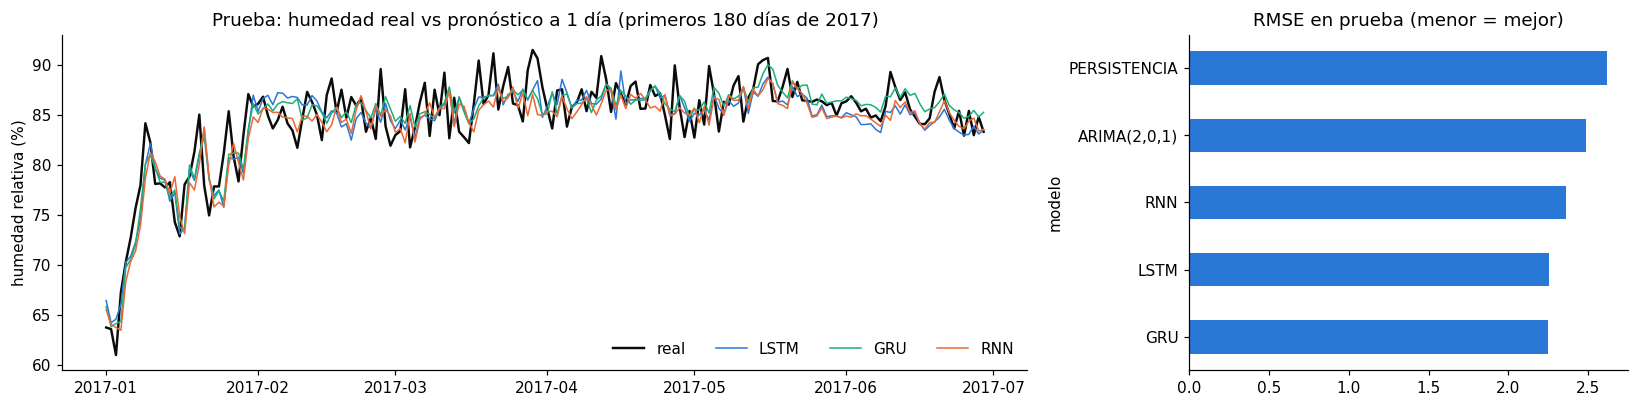

| modelo       |   RMSE |   MAE |   MAPE |
|:-------------|-------:|------:|-------:|
| RNN          |  2.362 | 1.810 |  2.503 |
| LSTM         |  2.253 | 1.762 |  2.450 |
| GRU          |  2.252 | 1.768 |  2.462 |
| PERSISTENCIA |  2.620 | 2.051 |  2.861 |
| ARIMA(2,0,1) |  2.488 | 1.916 |  2.676 |

In [25]:
filas_te, preds_te = [], {}
for celda in ("rnn", "lstm", "gru"):
    met, p, real = metricas_reg(modelos_b[celda][0], V14, "prueba"); preds_te[celda.upper()] = p
    filas_te.append({"modelo": celda.upper(), **met})
for nombre, pred in (("PERSISTENCIA", persist), ("ARIMA(2,0,1)", arima_pred)):
    filas_te.append({"modelo": nombre, **metricas_serie(pred, "prueba")})
tabla_b_te = pd.DataFrame(filas_te).set_index("modelo")
R2["b4_prueba"] = tabla_b_te.round(4).to_dict(orient="index"); R2["b3_validacion"] = tabla_b.round(4).to_dict(orient="index")

fechas_te = V14["prueba"][2]; tramo = slice(0, 180)
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(fechas_te[tramo], real[tramo], color="#0b0b0b", lw=1.6, label="real")
for k, c in zip(["LSTM", "GRU", "RNN"], ["#2a78d6", "#1baf7a", "#eb6834"]):
    axes[0].plot(fechas_te[tramo], preds_te[k][tramo], color=c, lw=1, label=k)
axes[0].set_ylabel("humedad relativa (%)"); axes[0].set_title("Prueba: humedad real vs pronóstico a 1 día (primeros 180 días de 2017)")
axes[0].legend(frameon=False, ncol=4)
tabla_b_te["RMSE"].sort_values().plot.barh(ax=axes[1], color="#2a78d6"); axes[1].set_title("RMSE en prueba (menor = mejor)")
fig.tight_layout(); fig.savefig(FIG / "b4_prueba.png", bbox_inches="tight"); plt.show()
ver_tabla(tabla_b_te.round(3))

## B5 · Evidencia del desvanecimiento del gradiente
La actividad pide al menos una vía; aquí se usan las dos.
1. **Traza de normas de gradiente:**
   - Con una ventana de **60 días**, se pregunta: si cambiara el clima de hace *k* días, ¿cuánto cambiaría la predicción de hoy?
   - Se mide con la norma de $\partial \hat{y} / \partial x_{t-k}$ para *k* = 1…60, promediada sobre 256 ventanas de validación y dividida por la del día más reciente.
   - Si cae a casi 0, la red es "ciega" a esos días: es el desvanecimiento.
2. **Desempeño con dependencias largas:** las tres celdas se reentrenan con ventana de 60 días y se compara su RMSE de validación.

**Qué hace el bloque de código:** construye las ventanas de 60 días, entrena las tres celdas (y guarda sus pesos), calcula la traza de gradiente de cada una y grafica ambas evidencias. La ventana de 60 días es además la que usa la fusión (decisión D3 de la Fase 1).

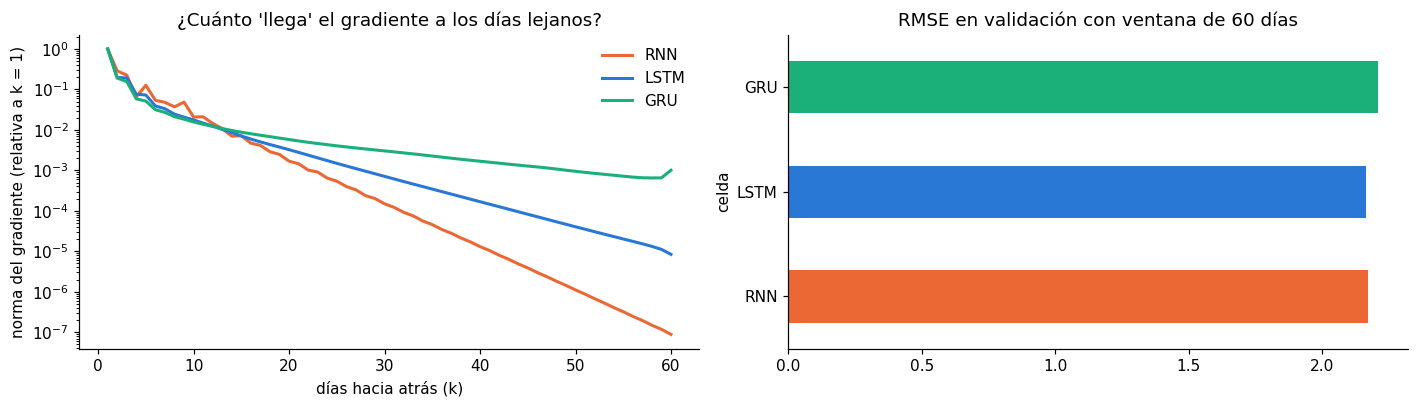

{'RNN': 'k=30: 1.49e-04 | k=60: 8.85e-08', 'LSTM': 'k=30: 7.11e-04 | k=60: 8.41e-06', 'GRU': 'k=30: 3.03e-03 | k=60: 1.01e-03'}


| celda   |   mejor_epoca |   RMSE |   MAE |   MAPE |
|:--------|--------------:|-------:|------:|-------:|
| RNN     |        22 |  2.170 | 1.709 |  2.463 |
| LSTM    |        22 |  2.164 | 1.689 |  2.425 |
| GRU     |        17 |  2.211 | 1.724 |  2.467 |

In [26]:
V60 = ventanas(60)
modelos_60, filas_60 = {}, []
for celda in ("rnn", "lstm", "gru"):
    m, _, ep, _ = entrenar_rec(celda, V60, f"{celda}_w60"); modelos_60[celda] = m
    filas_60.append({"celda": celda.upper(), "mejor_epoca": ep, **metricas_reg(m, V60, "validacion")[0]})
tabla_60 = pd.DataFrame(filas_60).set_index("celda")

def traza_gradiente(modelo, X):
    x = X[:256].clone().requires_grad_(True)
    modelo(x)[0].sum().backward()
    g = x.grad.norm(dim=2).mean(0).numpy()          # norma por paso de tiempo
    return g[::-1] / g[-1]                           # índice 0 = día más reciente (k = 1), normalizado

trazas = {c.upper(): traza_gradiente(modelos_60[c], V60["validacion"][0]) for c in ("rnn", "lstm", "gru")}
R2["b5_ventana60_validacion"] = tabla_60.round(4).to_dict(orient="index")
R2["b5_gradiente_relativo"] = {k: {"k30": float(v[29]), "k60": float(v[59])} for k, v in trazas.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, c in zip(["RNN", "LSTM", "GRU"], ["#eb6834", "#2a78d6", "#1baf7a"]):
    axes[0].semilogy(range(1, 61), trazas[k], color=c, lw=2, label=k)
axes[0].set_xlabel("días hacia atrás (k)"); axes[0].set_ylabel("norma del gradiente (relativa a k = 1)")
axes[0].set_title("¿Cuánto 'llega' el gradiente a los días lejanos?"); axes[0].legend(frameon=False)
tabla_60["RMSE"].plot.barh(ax=axes[1], color=["#eb6834", "#2a78d6", "#1baf7a"]); axes[1].set_title("RMSE en validación con ventana de 60 días")
fig.tight_layout(); fig.savefig(FIG / "b5_desvanecimiento.png", bbox_inches="tight"); plt.show()
print({k: f"k=30: {v[29]:.2e} | k=60: {v[59]:.2e}" for k, v in trazas.items()})
ver_tabla(tabla_60.round(3))

**Elección de la celda.** El bloque siguiente aplica este criterio: si la GRU queda a menos de un 2 % del RMSE de validación de la LSTM, se elige la **GRU**, porque hace lo mismo con menos parámetros.

In [27]:
CELDA_B = "gru" if tabla_b.loc["GRU", "val_RMSE"] <= tabla_b.loc["LSTM", "val_RMSE"] * 1.02 else "lstm"
R2["b_celda_elegida"] = CELDA_B.upper()
print("Celda elegida para la rama B y la fusión:", CELDA_B.upper(),
      "| parámetros GRU vs LSTM:", tabla_b.loc["GRU", "parametros"], "vs", tabla_b.loc["LSTM", "parametros"])

Celda elegida para la rama B y la fusión: GRU | parámetros GRU vs LSTM: 13889 vs 18497


**Lectura de la evidencia.**
- **Traza del gradiente:** a 60 días, la RNN simple conserva apenas **9·10⁻⁸** del gradiente del día más reciente, la LSTM **8·10⁻⁶** y la GRU **1·10⁻³**. La RNN es prácticamente ciega a lo que pasó hace dos meses: eso es el desvanecimiento. Las compuertas de la LSTM y la GRU lo mitigan.
- **Desempeño con 60 días:** el RMSE de validación es casi igual en las tres (RNN 2,17; LSTM 2,16; GRU 2,21). **No es una contradicción.** La humedad de mañana depende sobre todo de los últimos días (ACF a 1 día de 0,97), así que esta tarea casi no necesita memoria larga. La ventaja de las compuertas aparece cuando la dependencia es larga.
- **Prueba (ventana de 14):** GRU y LSTM empatan (RMSE de 2,25) y superan a la RNN (2,36), a ARIMA (2,49) y a la persistencia (2,62).

**Criterio GRU frente a LSTM:**
- La **GRU** se elige cuando rinde igual: tiene un 25 % menos de parámetros, entrena más rápido y es más simple de servir en la API de la Fase 3. Además, su gradiente llega mejor a los días lejanos, lo que es útil como codificador de 60 días para la fusión.
- La **LSTM** se preferiría con dependencias muy largas y muchos datos.
- La **RNN simple** solo sirve aquí como contraste.

# RAMA C · Fusión multimodal
## C1 · Alineación: la decisión más crítica
- **Clave:** `(sitio = CIIDEA, fecha EXIF de la foto)`. A cada foto se le asigna la secuencia de los **60 días de clima anteriores** a su fecha, sin incluir ese mismo día.
- **Tipo de alineación: AGREGADA, no co-registro por hoja.**
  - Todas las fotos se tomaron en un único sitio y en solo **5 días** (abril y mayo de 2019).
  - Por eso hay **5 secuencias climáticas distintas** para 1.560 fotos, y todas las hojas de un mismo día comparten exactamente el mismo clima.

**Qué hace este bloque:**
1. Ubica en la serie la posición de cada fecha de foto con `searchsorted`. La última foto (2019-05-02) cae justo después del fin de la serie, y su ventana termina el día anterior.
2. Construye las 5 ventanas de 60 días y resume el clima medio de cada una.
3. Pasa cada ventana por la celda recurrente elegida en B (con ventana de 60 días) para obtener $z_{seq}$, un vector de 64 números por fecha.
4. **Mide cuánto varían esos 5 vectores** frente a la variación normal del clima en 18 años. Si varían muy poco, el clima casi no puede aportar información.

In [28]:
fechas_foto = sorted(tabla["fecha_txt"].unique())
idx_fecha = {f: int(serie.index.searchsorted(pd.Timestamp(f))) for f in fechas_foto}   # la ventana termina el día anterior a la foto
X60_foto = torch.tensor(np.stack([X_norm[i - 60:i] for i in idx_fecha.values()]))
clima_fecha = pd.DataFrame([{"fecha": f, **serie.iloc[i - 60:i][VARS].mean().round(2).to_dict(),
                             "fotos": int((tabla["fecha_txt"] == f).sum())} for f, i in idx_fecha.items()]).set_index("fecha")
encoder = modelos_60[CELDA_B]
with torch.no_grad():
    Z_fecha = encoder(X60_foto)[1].numpy()                  # z_seq: un vector de 64 por fecha
var_entre = Z_fecha.std(0).mean(); var_ref = encoder(V60["entrenamiento"][0][:2000])[1].detach().numpy().std(0).mean()
R2["c1_alineacion"] = {"fechas": fechas_foto, "secuencias_distintas": len(fechas_foto), "clima_medio_60d": clima_fecha.to_dict(orient="index"),
                       "dispersion_zseq_entre_fechas": float(var_entre), "dispersion_zseq_18_anios": float(var_ref)}
print(f"Dispersión del embedding climático entre las 5 fechas: {var_entre:.3f} | en 18 años de días: {var_ref:.3f} "
      f"→ las fechas de las fotos ocupan un {100 * var_entre / var_ref:.0f} % de la variabilidad climática habitual")
ver_tabla(clima_fecha)

Dispersión del embedding climático entre las 5 fechas: 0.056 | en 18 años de días: 0.197 → las fechas de las fotos ocupan un 29 % de la variabilidad climática habitual


| fecha      |    T2M |   RH2M |   PRECTOTCORR |   WS2M |   fotos |
|:-----------|-------:|-------:|--------------:|-------:|--------:|
| 2019-04-09 | 25.800 | 85.820 |        10.730 |  1.570 |  92 |
| 2019-04-10 | 25.790 | 85.880 |        10.700 |  1.570 | 422 |
| 2019-04-11 | 25.790 | 85.800 |        10.450 |  1.560 | 766 |
| 2019-05-01 | 25.670 | 86.150 |         8.640 |  1.530 | 132 |
| 2019-05-02 | 25.660 | 86.210 |         8.630 |  1.540 | 148 |

### ¿Qué significa que la fecha esté "confundida" con el celular?
Dos variables están **confundidas** cuando siempre aparecen juntas, y por eso no se puede separar el efecto de una del de la otra. La tabla siguiente cruza la fecha de cada foto con el celular que la tomó:

In [29]:
cruce = pd.crosstab(tabla["fecha_txt"], tabla["dispositivo"].str.replace("samsung ", ""), margins=True, margins_name="total")
R2["c1_fecha_vs_celular"] = cruce.to_dict()
ver_tabla(cruce)

| fecha_txt   |   SM-G610M |   SM-J200M |   SM-J320H |   SM-J700M |    total |
|:------------|-----------:|-----------:|-----------:|-----------:|---------:|
| 2019-04-09  |      0 |     92 |      0 |      0 |   92 |
| 2019-04-10  |      0 |    230 |      0 |    192 |  422 |
| 2019-04-11  |    313 |    157 |      0 |    296 |  766 |
| 2019-05-01  |      0 |    132 |      0 |      0 |  132 |
| 2019-05-02  |      0 |      0 |    148 |      0 |  148 |
| total       |    313 |    611 |    148 |    488 | 1560 |

**Lectura.**
- Cada día se usaron entre uno y tres celulares, y varios celulares solo aparecen en un día: el SM-J320H solo el 2019-05-02 y el SM-G610M solo el 2019-04-11. El SM-J200M es el único presente en casi todas las fechas.
- Por lo tanto, saber la **fecha** equivale casi a saber **qué cámara** tomó la foto.
- **Consecuencia para la fusión:** si el modelo "aprovechara" el clima (que cambia con la fecha), podría estar aprendiendo en realidad diferencias de **cámara** (color, nitidez), no de clima.
- Por eso la ablación incluye una **prueba de permutación**: se barajan los climas entre las fotos. Si el resultado no cambia, el modelo no está usando ni el clima ni ese atajo de la cámara.

## C2 · Modelo de fusión tardía y ablación
**Representaciones de entrada:**
- **$z_{img}$:** los 1.280 rasgos que la EfficientNet-B0 de la rama A calcula antes de su capa final (red congelada).
  - Para **entrenamiento** se calculan 3 vistas por foto (original + 2 aumentadas). La CNN ya se ajustó con esas mismas fotos, así que sus rasgos de entrenamiento son "más fáciles" que los de fotos nuevas; las vistas aumentadas los acercan a cómo se verá una foto nueva.
- **$z_{seq}$:** el último estado oculto (64) de la GRU de 60 días de la rama B (red congelada).

**Fusión tardía** (Baltrušaitis et al., 2019):
- Cada modalidad se procesa por su cuenta y se unen sus representaciones al final.
- $\hat{y} = \sigma\big(W_{fus}\,[\,\mathrm{ReLU}(W_{img} z_{img}) \,\Vert\, z_{seq}\,] + b_{fus}\big)$, con una capa intermedia de 32 neuronas.
- Se aplica Dropout 0,5 a la entrada de la imagen y una tasa de aprendizaje de 3·10⁻⁴. Con una tasa mayor y sin Dropout, la cabeza memorizaba los rasgos de entrenamiento en la primera época.
- **Objetivo:** la **alerta binaria** de la Fase 1 (afectada sí/no), con pérdida BCE, parada temprana en validación y el umbral por costo elegido en validación.

**Ablación**, con la misma partición, semilla y regla de umbral:

| Modelo | Entrada |
|---|---|
| Solo imagen | $z_{img}$ |
| Solo serie | $z_{seq}$ |
| Fusión | $z_{img} \Vert z_{seq}$ |
| Fusión con clima permutado | Igual que la fusión, pero barajando el clima entre fotos |

**Qué hace el bloque de código:** calcula los rasgos de imagen, define la clase `Fusion` y el bucle de entrenamiento, entrena los tres modelos (guardando sus pesos), aplica la permutación y arma la tabla en **prueba** junto al MLP de la Fase 1.

In [30]:
VISTAS_C = 3

def rasgos_cnn(df, vistas=1):
    m = modelo_ft; m.eval(); Z = []
    torch.manual_seed(SEMILLA)
    for v in range(vistas):
        with torch.no_grad():
            for xb, _ in DataLoader(Hojas(df, T_EVAL if v == 0 else T_ENTRENO), batch_size=64):
                Z.append(m.avgpool(m.features(xb.to(DISPOSITIVO))).flatten(1).cpu().numpy())
    return np.concatenate(Z)

Zimg = {"entrenamiento": rasgos_cnn(split["entrenamiento"], VISTAS_C),
        "validacion": rasgos_cnn(split["validacion"]), "prueba": rasgos_cnn(split["prueba"])}
mu_img, sd_img = Zimg["entrenamiento"].mean(0), Zimg["entrenamiento"].std(0) + 1e-6
zseq_por_fecha = dict(zip(fechas_foto, Z_fecha))
mu_seq, sd_seq = Z_fecha.mean(0), Z_fecha.std(0) + 1e-6

def tensores_c(s, permutar_seq=False, aumentado=True):
    """z_img, z_seq y etiqueta de un subconjunto. En entrenamiento, 'aumentado' usa las 3 vistas por foto."""
    d = split[s]; n = len(d)
    reps = VISTAS_C if (s == "entrenamiento" and aumentado) else 1
    zi = (Zimg[s][:n * reps] - mu_img) / sd_img
    fechas = np.tile(d["fecha_txt"].values, reps)
    zs = np.stack([zseq_por_fecha[f] for f in fechas]); zs = (zs - mu_seq) / sd_seq
    if permutar_seq:
        zs = zs[np.random.default_rng(SEMILLA).permutation(len(zs))]
    y = torch.tensor(np.tile(d["afectada"].values, reps), dtype=torch.float32)[:, None]
    return torch.tensor(zi, dtype=torch.float32), torch.tensor(zs, dtype=torch.float32), y

class Fusion(nn.Module):
    """modo: 'img' (solo imagen), 'seq' (solo serie) o 'fusion'. Salida: logit."""
    def __init__(self, modo, d_img=1280, d_seq=64, p_in=0.5):
        super().__init__(); self.modo = modo
        self.proy_img = nn.Sequential(nn.Dropout(p_in), nn.Linear(d_img, 64), nn.ReLU())
        d = {"img": 64, "seq": d_seq, "fusion": 64 + d_seq}[modo]
        self.cabeza = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, zi, zs):
        partes = {"img": [self.proy_img(zi)], "seq": [zs], "fusion": [self.proy_img(zi), zs]}[self.modo]
        return self.cabeza(torch.cat(partes, 1))

def entrenar_fusion(modo, epocas=300, paciencia=15, lr=3e-4, p_in=0.5, aumentado=True, guardar=True):
    fijar_semillas()
    tr, va = tensores_c("entrenamiento", aumentado=aumentado), tensores_c("validacion")
    modelo = Fusion(modo, p_in=p_in); optim = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=1e-4); bce = nn.BCEWithLogitsLoss()
    cargador = DataLoader(TensorDataset(*tr), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    mejor, sin_mejora = (math.inf, None, 0), 0
    for epoca in range(1, epocas + 1):
        modelo.train()
        for zi, zs, y in cargador:
            perdida = bce(modelo(zi, zs), y); optim.zero_grad(); perdida.backward(); optim.step()
        modelo.eval()
        with torch.no_grad():
            pv = bce(modelo(va[0], va[1]), va[2]).item()
        if pv < mejor[0] - 1e-4:
            mejor, sin_mejora = (pv, copy.deepcopy(modelo.state_dict()), epoca), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor[1]); modelo.eval()
    if guardar:
        torch.save({"modelo": mejor[1], "modo": modo, "mejor_epoca": mejor[2], "mu_img": mu_img, "sd_img": sd_img,
                    "mu_seq": mu_seq, "sd_seq": sd_seq, "celda_seq": CELDA_B, "p_in": p_in}, MODELOS / f"rama_c_{modo}.pth")
    return modelo, mejor

def puntaje(modelo, s, permutar_seq=False):
    zi, zs, y = tensores_c(s, permutar_seq)
    with torch.no_grad():
        return torch.sigmoid(modelo(zi, zs)).numpy().ravel(), y.numpy().ravel().astype(int)

ablacion, modelos_c = [], {}
for modo, nombre in (("img", "Solo imagen"), ("seq", "Solo serie"), ("fusion", "Fusión")):
    m, b = entrenar_fusion(modo); modelos_c[modo] = m
    s_va, y_va = puntaje(m, "validacion"); u = costo_umbral(y_va, s_va)
    s_te, y_te = puntaje(m, "prueba")
    ablacion.append({"modelo": nombre, "mejor_epoca": b[2], "auc_val": roc_auc_score(y_va, s_va), **metricas_bin(y_te, s_te, u)})
s_perm, y_te = puntaje(modelos_c["fusion"], "prueba", permutar_seq=True)
u_fus = [a for a in ablacion if a["modelo"] == "Fusión"][0]["umbral"]
ablacion.append({"modelo": "Fusión con clima permutado", "mejor_epoca": None, "auc_val": None, **metricas_bin(y_te, s_perm, u_fus)})
ablacion.append({"modelo": "MLP Fase 1 (referencia)", "auc": fase1["auc"], "recall": fase1["recall_afectada"], "precision": fase1["precision_afectada"],
                 "f1": fase1["f1_afectada"], "FN": fase1["FN"], "FP": fase1["FP"], "costo": fase1["costo"], "umbral": 0.22})
tabla_c = pd.DataFrame(ablacion).set_index("modelo")
R2["c2_ablacion_prueba"] = tabla_c.round(4).where(tabla_c.notna(), None).to_dict(orient="index")
ver_tabla(tabla_c[["auc_val", "umbral", "auc", "recall", "precision", "f1", "FN", "FP", "costo"]].astype(float).round(3))

| modelo                     |   auc_val |   umbral |   auc |   recall |   precision |    f1 |     FN |      FP |   costo |
|:---------------------------|----------:|---------:|------:|---------:|------------:|------:|-------:|--------:|--------:|
| Solo imagen                |     0.944 |    0.080 | 0.932 |    0.933 |       0.669 | 0.779 |  8 |  55 |  95 |
| Solo serie                 |     0.505 |    0.460 | 0.501 |    1 |       0.504 | 0.670 |  0 | 117 | 117 |
| Fusión                     |     0.943 |    0.240 | 0.930 |    0.899 |       0.817 | 0.856 | 12 |  24 |  84 |
| Fusión con clima permutado |   nan     |    0.240 | 0.930 |    0.899 |       0.843 | 0.870 | 12 |  20 |  80 |
| MLP Fase 1 (referencia)    |   nan     |    0.220 | 0.936 |    0.975 |       0.748 | 0.847 |  3 |  39 |  54 |

**Gráfico de la ablación:** la AUC (0,5 = azar, 1 = perfecto) y el costo 5·FN + FP de cada variante en prueba.

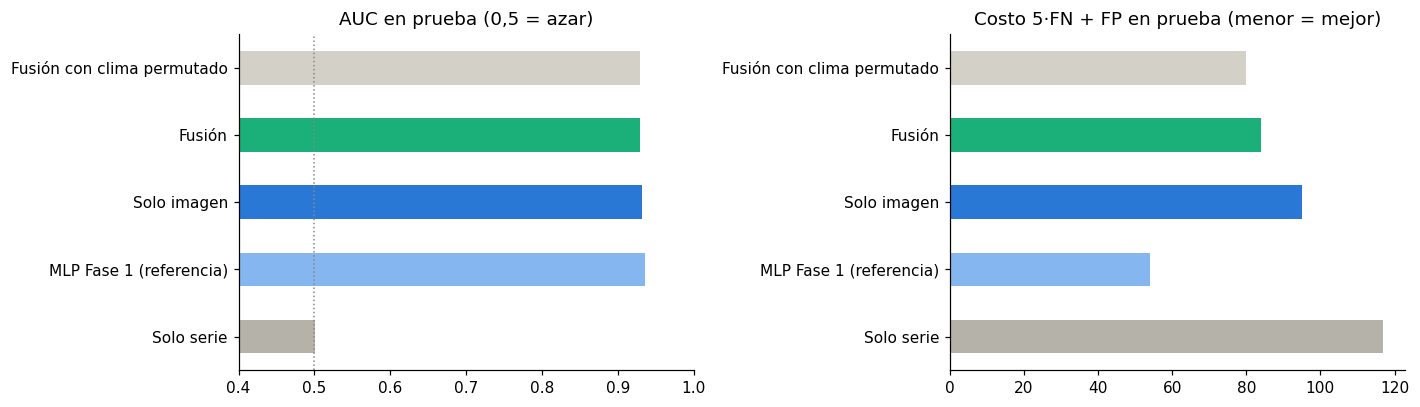

In [31]:
orden = ["Solo serie", "MLP Fase 1 (referencia)", "Solo imagen", "Fusión", "Fusión con clima permutado"]
colores = ["#b4b2a9", "#86b6ef", "#2a78d6", "#1baf7a", "#d3d1c7"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
tabla_c.loc[orden, "auc"].plot.barh(ax=axes[0], color=colores)
axes[0].axvline(0.5, color="#898781", ls=":", lw=1); axes[0].set_xlim(0.4, 1); axes[0].set_title("AUC en prueba (0,5 = azar)")
tabla_c.loc[orden, "costo"].plot.barh(ax=axes[1], color=colores); axes[1].set_title("Costo 5·FN + FP en prueba (menor = mejor)")
for ax in axes:
    ax.set_ylabel("")
fig.tight_layout(); fig.savefig(FIG / "c2_ablacion.png", bbox_inches="tight"); plt.show()

**Lectura de la ablación (honesta).**

| Modelo | AUC | Costo |
|---|---|---|
| Solo serie | 0,501 | — |
| Solo imagen | 0,932 | 95 |
| Fusión | 0,930 | 84 |
| Fusión con clima permutado | 0,930 | 80 |
| MLP Fase 1 | 0,936 | 54 |

- **Solo serie ≈ azar (0,50).** Hay solo 5 climas distintos, uno por día, y en cada día hay hojas sanas y afectadas casi en la misma proporción (V de Cramér 0,024 en la Fase 1). El clima no puede distinguir una hoja de otra del mismo día. Es lo esperado, y confirma que no hay fuga por la fecha.
- **La fusión no supera a la imagen sola,** y **barajar el clima entre fotos no cambia la AUC.** El modelo aprendió a ignorar el clima: tampoco está aprovechando el atajo de la cámara.
- **Es un resultado negativo válido,** por tres razones:
  - **Desalineación de escala:** el clima es de la finca, no de la hoja.
  - **Datos insuficientes:** solo hay 5 fechas.
  - **Redundancia:** el estado de la hoja ya refleja el clima pasado.
- **Las diferencias de costo** entre imagen, fusión y permutada (80 a 95) vienen de dónde cae el umbral, no de una mejor capacidad de ordenar.
- **¿Cuándo sí aportaría el clima?** Con fotos de muchas fincas y fechas, donde el clima previo varíe de verdad. Ahí la fusión podría anticipar el riesgo antes de que la lesión sea visible.

## C3 · Verificación de los pesos guardados (preparación para la Fase 3)
**Qué hace este bloque:**
1. Vuelve a cargar desde disco los pesos de las tres ramas en modelos nuevos.
2. Comprueba que predicen **exactamente lo mismo** que los modelos en memoria (`np.allclose`, tolerancia 1e-4). Es la misma prueba que hará la Fase 3 después de exportar.
3. Lista el tamaño de cada archivo `.pth`.

In [32]:
verif = {}
m = construir_effnet_ft(); m.load_state_dict(torch.load(RUTA_FT, weights_only=False)["modelo"]); m.eval()
x = torch.stack([T_EVAL(Image.open(DIR_HOJAS / a).convert("RGB")) for a in split["prueba"]["archivo"][:16]])
with torch.no_grad():
    verif["rama_a"] = bool(np.allclose(F.softmax(m(x), 1).numpy(), F.softmax(modelo_ft(x), 1).numpy(), atol=1e-4))
ck = torch.load(MODELOS / f"rama_b_{CELDA_B}_w60.pth", weights_only=False); mb = Recurrente(CELDA_B); mb.load_state_dict(ck["modelo"]); mb.eval()
with torch.no_grad():
    verif["rama_b"] = bool(np.allclose(mb(V60["prueba"][0][:64])[0].numpy(), encoder(V60["prueba"][0][:64])[0].numpy(), atol=1e-4))
ck = torch.load(MODELOS / "rama_c_fusion.pth", weights_only=False); mc = Fusion("fusion", p_in=ck["p_in"]); mc.load_state_dict(ck["modelo"]); mc.eval()
zi, zs, _ = tensores_c("prueba")
with torch.no_grad():
    verif["rama_c"] = bool(np.allclose(mc(zi, zs).numpy(), modelos_c["fusion"](zi, zs).numpy(), atol=1e-4))
R2["c3_verificacion_pesos"] = verif
pesos = {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted(MODELOS.glob("*.pth"))}
R2["pesos_MB"] = pesos
print(verif); pd.Series(pesos, name="MB")

{'rama_a': True, 'rama_b': True, 'rama_c': True}


rama_a_efficientnet_b0_ft.pth    16.35
rama_b_gru_w14.pth                0.06
rama_b_gru_w30.pth                0.06
rama_b_gru_w60.pth                0.06
rama_b_gru_w7.pth                 0.06
rama_b_lstm_w14.pth               0.08
rama_b_lstm_w30.pth               0.08
rama_b_lstm_w60.pth               0.08
rama_b_lstm_w7.pth                0.08
rama_b_rnn_w14.pth                0.02
rama_b_rnn_w60.pth                0.02
rama_c_fusion.pth                 0.36
rama_c_img.pth                    0.36
rama_c_seq.pth                    0.36
Name: MB, dtype: float64

## C4 · Comunicación al cliente
### Visualizaciones estáticas
**Qué hace este bloque:** genera tres figuras en lenguaje no técnico para el técnico de sanidad y las guarda en `resultados/fase2/cliente/`. Están comentadas en `LEEME_visualizaciones.md` y en el informe.
1. ¿Qué tan bien reconoce cada tipo de hoja?
2. ¿En qué momento del año se tomaron las fotos? (humedad típica frente a la de 2019).
3. Fase 1 frente a Fase 2: hojas enfermas que se escapan y falsas alarmas.

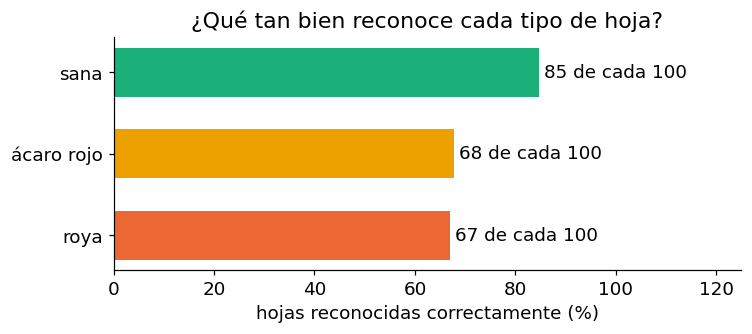

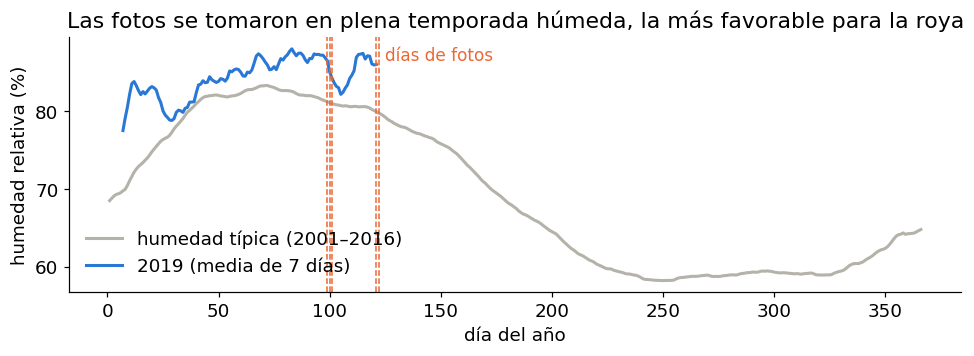

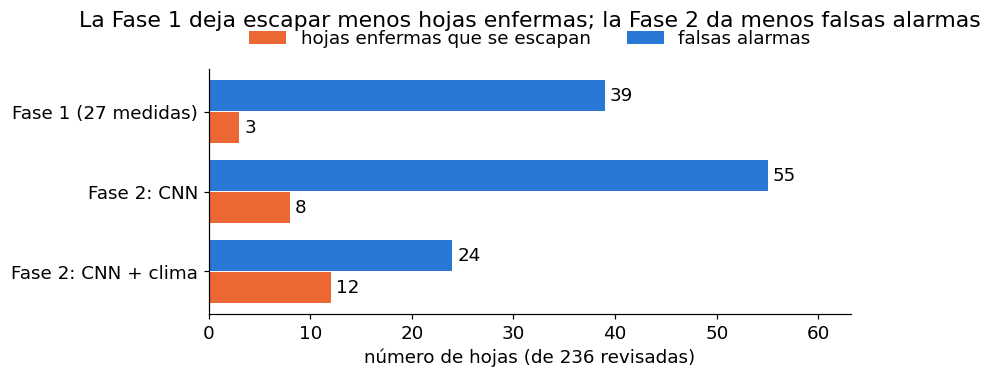

In [33]:
CLI = RES / "cliente"; CLI.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12})

# 1. ¿Qué tan bien reconoce cada tipo de hoja?
fig, ax = plt.subplots(figsize=(7, 3.2))
v = tabla_clase["recall"].values * 100
ax.barh(CLASES[::-1], v[::-1], color=[COLOR[c] for c in CLASES[::-1]], height=0.6)
for i, val in enumerate(v[::-1]):
    ax.text(val + 1, i, f"{val:.0f} de cada 100", va="center", fontsize=12)
ax.set_xlim(0, 125); ax.set_xlabel("hojas reconocidas correctamente (%)"); ax.set_title("¿Qué tan bien reconoce cada tipo de hoja?")
fig.tight_layout(); fig.savefig(CLI / "1_reconocimiento_por_tipo.png", bbox_inches="tight"); plt.show()

# 2. Clima de los días de las fotos frente a lo habitual en la finca
mensual = serie["RH2M"].groupby(serie.index.dayofyear).mean().rolling(15, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(mensual.index, mensual.values, color="#b4b2a9", lw=2, label="humedad típica (2001–2016)")
ax.plot(serie.loc["2019-01-01":"2019-05-01", "RH2M"].index.dayofyear, serie.loc["2019-01-01":"2019-05-01", "RH2M"].rolling(7).mean(),
        color="#2a78d6", lw=2, label="2019 (media de 7 días)")
for f in fechas_foto:
    ax.axvline(pd.Timestamp(f).dayofyear, color="#eb6834", ls="--", lw=1)
ax.text(pd.Timestamp(fechas_foto[-1]).dayofyear + 3, ax.get_ylim()[1] - 3, "días de fotos", color="#eb6834", fontsize=11)
ax.set_xlabel("día del año"); ax.set_ylabel("humedad relativa (%)"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Las fotos se tomaron en plena temporada húmeda, la más favorable para la roya")
fig.tight_layout(); fig.savefig(CLI / "2_clima_temporada.png", bbox_inches="tight"); plt.show()

# 3. Fase 1 frente a Fase 2: hojas enfermas que se escapan y falsas alarmas
comp = tabla_c.loc[["MLP Fase 1 (referencia)", "Solo imagen", "Fusión"], ["FN", "FP"]].astype(float)
comp.index = ["Fase 1 (27 medidas)", "Fase 2: CNN", "Fase 2: CNN + clima"]
fig, ax = plt.subplots(figsize=(8, 3.6)); y = np.arange(len(comp))
ax.barh(y + 0.2, comp["FN"], 0.38, color="#eb6834", label="hojas enfermas que se escapan")
ax.barh(y - 0.2, comp["FP"], 0.38, color="#2a78d6", label="falsas alarmas")
for i, (fn, fp) in enumerate(comp.values):
    ax.text(fn + 0.5, i + 0.2, int(fn), va="center"); ax.text(fp + 0.5, i - 0.2, int(fp), va="center")
ax.set_yticks(y, comp.index); ax.invert_yaxis(); ax.set_xlabel(f"número de hojas (de {len(split['prueba'])} revisadas)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
ax.set_xlim(0, comp.values.max() * 1.15)
ax.set_title("La Fase 1 deja escapar menos hojas enfermas; la Fase 2 da menos falsas alarmas", pad=28)
fig.tight_layout(); fig.savefig(CLI / "3_fase1_vs_fase2.png", bbox_inches="tight"); plt.show()
plt.rcParams.update({"font.size": 10})

### Tablero para el técnico (bonus)
**Qué hace este bloque:**
1. Guarda las predicciones de prueba (`predicciones_prueba.csv`).
2. Genera **`resultados/fase2/tablero_tecnico.html`**, un único archivo que se abre con doble clic, sin instalar nada y sin internet (Plotly va incluido).

**El tablero está pensado para el técnico de sanidad, no para un analista:**
1. **Resumen de la visita:** cuántas plantas tienen posible roya, posible ácaro rojo o ninguna alerta.
2. **Las 5 plantas que más urge visitar.**
   - **Orden:** primero las de posible roya (se propaga rápido con humedad) y luego las de ácaro. Dentro de cada grupo, de mayor a menor probabilidad; si empatan, primero la que tuvo la semana previa más húmeda.
   - **Cada tarjeta muestra:**
     - la hoja que generó la alerta y qué tendría probablemente;
     - la **humedad de los 7 días antes de la foto** frente a **lo normal en esos mismos días** (promedio de los 5 años anteriores), con una frase que la interpreta;
     - qué revisar en campo.
3. **Cómo leerlo:** probabilidad, humedad y límites, en lenguaje sencillo.

La humedad es **contexto de riesgo**: la probabilidad sale solo de la foto, porque en la Fase 2 el clima no mejoró la predicción por hoja.

In [34]:
pred_tablero = split["prueba"][["archivo", "planta", "cara", "fecha_txt", "clase3"]].copy()
pred_tablero[["p_sana", "p_acaro", "p_roya"]] = prob_te_a
pred_tablero["p_afectada"] = 1 - pred_tablero["p_sana"]
pred_tablero.to_csv(RES / "predicciones_prueba.csv", index=False)

sys.path.insert(0, str(ROOT / "app"))
from generar_tablero import generar
ruta_tablero, top5 = generar(ROOT)
print("Tablero generado:", ruta_tablero.relative_to(ROOT), f"({ruta_tablero.stat().st_size / 1e6:.1f} MB) · ábralo con doble clic")
ver_tabla(top5.rename(columns={"planta": "planta", "sospecha": "posible", "p_lesion": "probabilidad", "fecha_txt": "fecha de la foto",
                             "humedad_extra": "humedad sobre lo normal (puntos)"}).reset_index(drop=True))

Tablero generado: resultados\fase2\tablero_tecnico.html (4.7 MB) · ábralo con doble clic


|    | planta   | posible   |   probabilidad | fecha de la foto   |   humedad sobre lo normal (puntos) |
|---:|:---------|:----------|---------------:|:-------------------|-----------------------------------:|
|  0 | C1P7     | Roya      |          0.999 | 2019-05-02         |                              6.333 |
|  1 | C5P5     | Roya      |          0.998 | 2019-05-01         |                              6.232 |
|  2 | C11P13   | Roya      |          1 | 2019-04-11         |                              3.368 |
|  3 | C12P23   | Roya      |          0.999 | 2019-04-11         |                              3.368 |
|  4 | C7P36    | Roya      |          0.999 | 2019-04-11         |                              3.368 |

## Exportación de resultados
**Qué hace este bloque:** guarda en disco lo que necesitan el informe y la Fase 3:
- **`resultados_fase2.json`:** todas las cifras que cita el informe.
- **`historias_fase2.json`:** las curvas de entrenamiento.
- **`manifiesto_particion_3clases.csv`:** qué foto va a qué subconjunto y con qué clase, insumo para organizar las carpetas `train/val/test` de la Fase 3.

In [35]:
manifiesto = tabla[["archivo", "planta", "subconjunto", "clase3", "afectada", "fecha_txt"]]
manifiesto.to_csv(RES / "manifiesto_particion_3clases.csv", index=False)
historias = {"rama_a_ft": hist_ft, **{f"rama_b_{c}_w14": modelos_b[c][1] for c in modelos_b}}
(RES / "historias_fase2.json").write_text(json.dumps(historias), encoding="utf-8")
(RES / "resultados_fase2.json").write_text(json.dumps(R2, ensure_ascii=False, indent=2,
                                                      default=lambda o: o.tolist() if isinstance(o, np.ndarray) else (o.item() if hasattr(o, "item") else str(o))),
                                           encoding="utf-8")
print("Exportado. Rama A:", ELEGIDO_A, "| Rama B:", CELDA_B.upper(), "| Fusión AUC prueba:", round(tabla_c.loc["Fusión", "auc"], 3))

Exportado. Rama A: EfficientNet-B0 · FT | Rama B: GRU | Fusión AUC prueba: 0.93
